# NYC facade typologies: clustering buildings by facade materials and inspection history

**Team:** Amelia, Jerome, Kazuko, Sahil
**Course:** AI Methods I – Day 3: Unsupervised learning (IAAC MaAI 2026/27)

## 0. Introduction and problem definition

In New York City, every building taller than 6 stories must have its facade inspected every 5 years (FISP, Local Law 11). Each inspection ends with a status:
**SAFE**, **SWARMP** (safe with a repair and maintenance programme) or **UNSAFE**. On Day 2 we *predicted* the UNSAFE status. Today there is no target:
we ask **which kinds of buildings exist in the FISP stock**, judged by **what their facades are made of** and **how they have behaved over the inspection cycles**.

### Use case

- **Who:** the facade unit of the NYC Department of Buildings (DOB), facade engineering consultants and retrofit programme planners.
- **For what:** to split the FISP building stock into a handful of **building types**, each with its own inspection guidance, repair
  specification or enforcement programme. A terra-cotta pre-war tower, a glass curtain wall and a stucco-clad apartment block need different
  specialists, and a building that is UNSAFE in every cycle needs enforcement more than guidance.
- **What makes a group useful:** we can **name** it from its materials and history, we can **find it on the map**, and a **different action** makes sense for it.

### Unit of analysis

**One building**, identified by its BIN (DOB Building Identification Number). The cleaned Day 2 table has one row per **filing** (one report per
building and cycle, plus amended and follow-up reports): we aggregate the filings of each building into one row.

### Data

1. **FISP filings:** the cleaned table of our Day 2 assignment (NYC Open Data, *DOB NOW: Safety – Facades Compliance Filings*,
   [data.cityofnewyork.us/d/xubg-57si](https://data.cityofnewyork.us/d/xubg-57si), downloaded 2026-10-23), produced by our Day 2 notebook
   [`data_cleaning_and_EDA.ipynb`](https://github.com/iaac-maai/group1_day2_assignment/blob/main/notebook/data_cleaning_and_EDA.ipynb).
   It is committed as `data/facades_clean.csv` (67,659 filings, 42 columns), so this notebook runs on its own. Street addresses are in that
   table, but we **do not** carry them into the published dataset.
2. **PLUTO** (NYC Department of City Planning, *Primary Land Use Tax Lot Output*, [data.cityofnewyork.us/d/64uk-42ks](https://data.cityofnewyork.us/d/64uk-42ks)):
   one row per tax lot with its **latitude / longitude**, **year built** and **number of floors**. The filings have no coordinates, but they have
   the borough, block and lot (BBL) of each building, which is the key of PLUTO. We use PLUTO **only to map and interpret** the clusters, never to build them.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shutil
import joblib
import sklearn
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
DATASET_DIR = Path("..") / "dataset"
for d in (FIG_DIR, MODEL_DIR, DATASET_DIR):
    d.mkdir(exist_ok=True)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

STATUS_COLORS = {"SAFE": "#55A868", "SWARMP": "#DD8452", "UNSAFE": "#C44E52"}
BOROUGH_ORDER = ["MANHATTAN", "BRONX", "BROOKLYN", "QUEENS", "STATEN ISLAND"]

# ---- What this cell does ----
# Setup. We import every library used in the notebook: pandas / numpy for tables, matplotlib / seaborn for charts,
# scikit-learn for scaling, PCA, t-SNE, clustering and metrics, scipy for the dendrogram, joblib to save the model.
# The four folders are one level up from notebook/ (relative paths, so the notebook runs on any computer).
# RANDOM_STATE = 42 is used for every random step, so the results are the same at every run.
# STATUS_COLORS and BOROUGH_ORDER keep the same colours and order in every chart.

scikit-learn 1.9.1 | pandas 3.1.0 | numpy 2.5.4


### 0.1 Load the cleaned filings

In [2]:
filings = pd.read_csv(DATA_DIR / "facades_clean.csv")
print(filings.shape)
filings.head()

# ---- What this cell does ----
# Load the cleaned filings produced by our Day 2 notebook: one row = one FISP report (67,659 rows, 42 columns).
# .head() shows the first 5 rows so we can see the columns.

(67659, 42)


,TR6_NO,BIN,BOROUGH,BLOCK,LOT,HOUSE_NO,STREET_NAME,FILING_TYPE,CYCLE,SEQUENCE_NO,FILING_YEAR,FILING_STATUS,IS_UNSAFE,PRIOR_STATUS,HAS_PRIOR_CYCLE,EXTERIOR_WALL_TYPES,EXTERIOR_WALL_MATERIALS,WALL_TYPE_BRICK_MASONRY,WALL_TYPE_OTHER,WALL_TYPE_MASONRY_LOAD_BEARING_WALL,WALL_TYPE_TERRA_COTTA,WALL_TYPE_MASONRY_CAVITY_WALL,WALL_TYPE_STEEL_FRAME,WALL_TYPE_CONCRETE,WALL_TYPE_CONCRETE_FRAME,MATERIAL_MASONRY,MATERIAL_OTHER,MATERIAL_TERRA_COTTA,MATERIAL_NATURAL_STONE,MATERIAL_CONCRETE,MATERIAL_STUCCO_EIFS,MATERIAL_GLASS,MATERIAL_METAL,FIELD_INSPECTION_COMPLETED_DATE,FILING_DATE,PRIOR_CYCLE_FILING_DATE,QEWI_SIGNED_DATE,DAYS_INSPECTION_TO_FILING,LATE_FILING_AMT,FAILURE_TO_FILE_AMT,FAILURE_TO_CORRECT_AMT,TOTAL_PENALTY_AMT
0,TR6-611824-NA-I1,4436310.0,QUEENS,16114.0,2,8201,HAMMELS BOULEVARD,INITIAL,6.0,4.0,2009.0,SAFE,0,SAFE,1,OTHER,OTHER,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2008-03-11,2009-10-16,2003-03-25,2009-09-30,584.0,0.0,0.0,0.0,0.0
1,TR6-611612-NA-A1,4208850.0,QUEENS,9757.0,23,90-04,161 STREET,AMENDED,6.0,1.0,2010.0,SWARMP,0,NaN,0,OTHER,OTHER,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,2010-12-15,NaN,NaN,NaN,44000.0,15000.0,707500.0,766500.0
2,TR6-802744-8A-I1,1019150.0,MANHATTAN,894.0,52,148,EAST 39 STREET,INITIAL,8.0,1.0,2018.0,SWARMP,0,SWARMP,1,BRICK MASONRY,MASONRY,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2018-03-22,2018-04-09,2012-02-21,2018-09-27,18.0,3500.0,1000.0,0.0,4500.0
3,TR6-709724-7A-I1,3326542.0,BROOKLYN,3576.0,1,300,DUMONT AVENUE,INITIAL,7.0,7.0,2012.0,SAFE,0,SAFE,1,OTHER,OTHER,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2012-10-25,2012-12-03,2010-02-16,2012-11-30,39.0,0.0,0.0,0.0,0.0
4,TR6-905693-9C-I1,1048411.0,MANHATTAN,1522.0,158,1442,LEXINGTON AVENUE,INITIAL,9.0,1.0,2022.0,UNSAFE,1,NaN,0,MASONRY LOAD-BEARING WALL,MASONRY; NATURAL STONE,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2022-07-20,2022-08-04,NaN,2022-08-01,15.0,150500.0,36000.0,108830.0,295330.0


In [3]:
print(filings["FILING_TYPE"].value_counts(), "\n")
print(filings["FILING_STATUS"].value_counts(), "\n")
print("Distinct buildings (BIN):", filings["BIN"].nunique(), "| filings without BIN:", filings["BIN"].isna().sum())

# ---- What this cell does ----
# Quick counts: how many filings of each type (INITIAL = regular 5-year report, AMENDED / SUBSEQUENT = later
# corrections and follow-ups) and of each status (SAFE, SWARMP, UNSAFE), and how many different buildings (BIN) there are.

FILING_TYPE
INITIAL       54062
AMENDED        9382
SUBSEQUENT     4215
Name: count, dtype: int64 

FILING_STATUS
SAFE      28080
SWARMP    24467
UNSAFE    15112
Name: count, dtype: int64 

Distinct buildings (BIN): 15767 | filings without BIN: 12


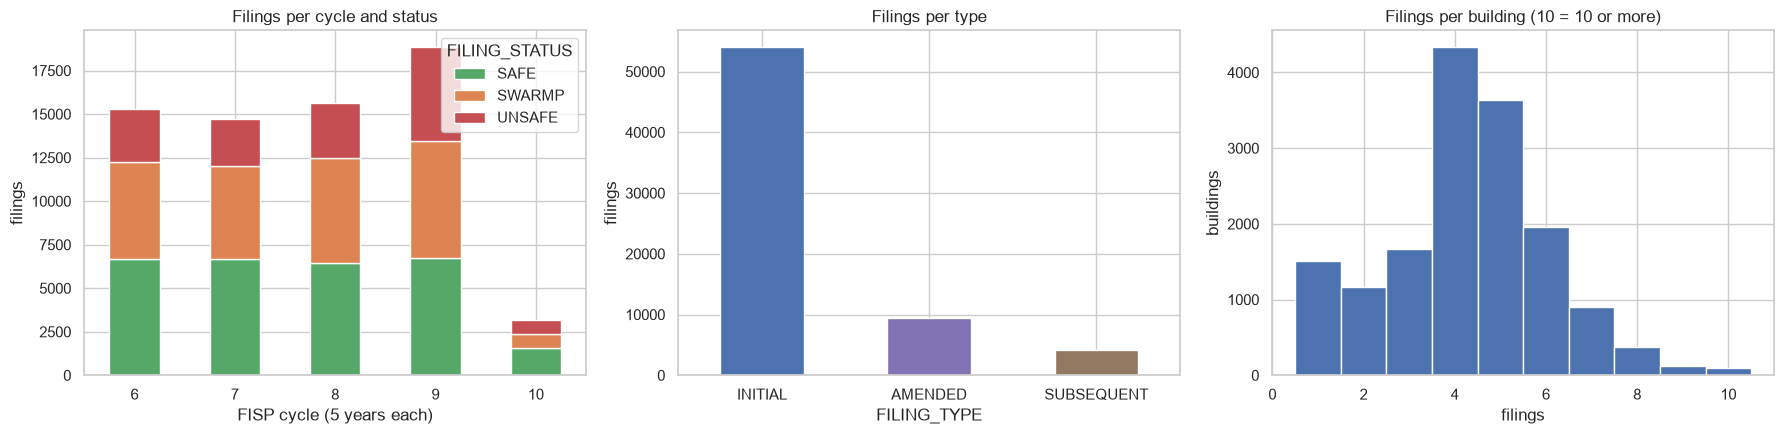

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

counts = filings.groupby(["CYCLE", "FILING_STATUS"]).size().unstack()[list(STATUS_COLORS)]
counts.index = counts.index.astype(int)
counts.plot.bar(stacked=True, color=STATUS_COLORS, ax=axes[0], rot=0)
axes[0].set(title="Filings per cycle and status", xlabel="FISP cycle (5 years each)", ylabel="filings")

filings["FILING_TYPE"].value_counts().plot.bar(ax=axes[1], color=["#4C72B0", "#8172B3", "#937860"], rot=0)
axes[1].set(title="Filings per type", ylabel="filings")

per_bin = filings.groupby("BIN").size()
axes[2].hist(per_bin.clip(upper=10), bins=np.arange(0.5, 11.5), color="#4C72B0")
axes[2].set(title="Filings per building (10 = 10 or more)", xlabel="filings", ylabel="buildings")

fig.tight_layout()
fig.savefig(FIG_DIR / "01_filings_overview.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# Three overview charts of the raw filings:
# 1) filings per cycle, stacked by status (shows that cycle 10 has just started);
# 2) filings per type;
# 3) how many filings each building has (most have 4-5), which is why we need one row per building.
# fig.savefig writes the chart to figures/ so it can be used in the README.

The table holds **67,659 filings** for about **15,800 buildings**. *INITIAL* filings are the regular 5-yearly reports; *AMENDED* and *SUBSEQUENT*
filings come later, after repairs or after an UNSAFE result. Cycle 10 has just started, so it has few filings. Most buildings have **4 to 5 filings**:
one per cycle, plus follow-ups. This is a **time series of reports per building**, so the natural unit for the question "what kind of building is
this?" is **one building**, not one report.

### 0.2 From filings to buildings

We aggregate every building's filings into one row. The full list of features and the reasons for each come in section 1; here we build the table.

In [5]:
filings = filings.dropna(subset=["BIN"]).copy()
filings["BIN"] = filings["BIN"].astype("int64")
MATERIALS = [c for c in filings if c.startswith("MATERIAL_")]
WALL_TYPES = [c for c in filings if c.startswith("WALL_TYPE_")]

initial = filings[filings["FILING_TYPE"] == "INITIAL"].sort_values(["BIN", "CYCLE"])
g_all = filings.groupby("BIN")
g_ini = initial.groupby("BIN")

def most_frequent(s):
    s = s.dropna()
    return s.mode().iat[0] if len(s) else np.nan

buildings = pd.DataFrame({
    "BOROUGH": g_all["BOROUGH"].agg(most_frequent),
    "BLOCK": g_all["BLOCK"].agg(most_frequent),
    "LOT": g_all["LOT"].agg(most_frequent),
    "n_cycles": g_ini["CYCLE"].nunique(),
    "first_cycle": g_ini["CYCLE"].min(),
    "last_cycle": g_ini["CYCLE"].max(),
    "first_filing_year": g_ini["FILING_YEAR"].min(),
    "last_filing_year": g_ini["FILING_YEAR"].max(),
    "n_unsafe": g_ini["FILING_STATUS"].agg(lambda s: (s == "UNSAFE").sum()),
    "n_swarmp": g_ini["FILING_STATUS"].agg(lambda s: (s == "SWARMP").sum()),
    "n_safe": g_ini["FILING_STATUS"].agg(lambda s: (s == "SAFE").sum()),
    "latest_status": g_ini["FILING_STATUS"].last(),
    "n_followups": g_all["FILING_TYPE"].agg(lambda s: (s != "INITIAL").sum()),
    "total_penalty": g_all["TOTAL_PENALTY_AMT"].sum(),
    "failure_to_correct_penalty": g_all["FAILURE_TO_CORRECT_AMT"].sum(),
    "late_filing_penalty": g_all["LATE_FILING_AMT"].sum(),
})
buildings = buildings.join(g_all[MATERIALS + WALL_TYPES].max())
print("Buildings:", len(buildings), "| without an initial filing:", buildings["n_cycles"].isna().sum())

# ---- What this cell does ----
# From filings to buildings. We group the filings by BIN (building ID) and compute one row per building:
# - most_frequent(): the most common borough / block / lot of the building (ignores empty values);
# - from the INITIAL filings only: number of cycles, first / last cycle and year, counts of SAFE / SWARMP / UNSAFE, latest status;
# - from all filings: number of follow-up filings and the sums of the penalties;
# - materials and wall types: .max() = 1 if the material was listed in ANY of the building's reports.

Buildings: 15767 | without an initial filing: 0


A few buildings have only amended / follow-up filings (their initial report is not in the cleaned table). Without an initial filing we cannot
describe their inspection record, so we drop them. We also drop the buildings without a block or lot: they cannot be located. Some buildings list no material or wall type at all: we count those as 0 ("nothing listed")
instead of dropping them.

In [6]:
n_no_bbl = buildings[["BLOCK", "LOT"]].isna().any(axis=1).sum()
buildings = buildings.dropna(subset=["n_cycles", "BOROUGH", "BLOCK", "LOT"]).copy()
n_no_material = buildings[MATERIALS + WALL_TYPES].isna().any(axis=1).sum()
buildings[MATERIALS + WALL_TYPES] = buildings[MATERIALS + WALL_TYPES].fillna(0).astype(int)

int_cols = ["n_cycles", "first_cycle", "last_cycle", "first_filing_year", "last_filing_year",
            "n_unsafe", "n_swarmp", "n_safe", "n_followups", "BLOCK", "LOT"]
buildings[int_cols] = buildings[int_cols].astype(int)
buildings = buildings.reset_index()

print("Dropped for a missing block / lot:", n_no_bbl)
print("Buildings kept:", len(buildings), "| filled as 'no material listed':", n_no_material)
print("Duplicated BIN:", buildings["BIN"].duplicated().sum())
buildings.head()

# ---- What this cell does ----
# Clean the building table:
# - drop buildings with no initial filing or no block / lot (they can't be described or located);
# - buildings that list no material get 0 in every material column instead of an empty value;
# - convert the counts to integers and reset the index so BIN becomes a normal column;
# - check that every BIN appears only once.

Dropped for a missing block / lot: 4
Buildings kept: 15763 | filled as 'no material listed': 22
Duplicated BIN: 0


,BIN,BOROUGH,BLOCK,LOT,n_cycles,first_cycle,last_cycle,first_filing_year,last_filing_year,n_unsafe,n_swarmp,n_safe,latest_status,n_followups,total_penalty,failure_to_correct_penalty,late_filing_penalty,MATERIAL_MASONRY,MATERIAL_OTHER,MATERIAL_TERRA_COTTA,MATERIAL_NATURAL_STONE,MATERIAL_CONCRETE,MATERIAL_STUCCO_EIFS,MATERIAL_GLASS,MATERIAL_METAL,WALL_TYPE_BRICK_MASONRY,WALL_TYPE_OTHER,WALL_TYPE_MASONRY_LOAD_BEARING_WALL,WALL_TYPE_TERRA_COTTA,WALL_TYPE_MASONRY_CAVITY_WALL,WALL_TYPE_STEEL_FRAME,WALL_TYPE_CONCRETE,WALL_TYPE_CONCRETE_FRAME
0,1000005,MANHATTAN,4,7501,4,6,9,2006,2022,0,4,0,SWARMP,0,0.0,0.0,0.0,0,1,1,0,0,0,1,0,0,1,0,1,0,1,0,0
1,1000006,MANHATTAN,5,7501,4,6,9,2006,2022,2,0,2,UNSAFE,4,160400.0,126400.0,34000.0,1,1,0,0,0,0,1,0,0,1,0,0,1,0,0,0
2,1000007,MANHATTAN,5,10,5,6,10,2009,2026,1,2,2,SAFE,3,410000.0,382400.0,27600.0,1,0,0,1,1,1,1,1,1,1,0,0,1,1,0,0
3,1000016,MANHATTAN,8,44,4,6,9,2007,2022,2,0,2,SAFE,1,188750.0,165000.0,18750.0,1,1,0,0,0,0,0,0,1,1,1,0,0,0,0,0
4,1000018,MANHATTAN,9,1,4,6,9,2007,2023,0,3,1,SWARMP,0,83400.0,0.0,63400.0,1,1,0,0,0,0,1,1,0,1,0,0,0,1,0,0


### 0.3 Geolocate the buildings with PLUTO

To draw the clusters on a **map of New York**, we join each building to its tax lot in PLUTO with the **BBL** (borough code × 10⁹ + block × 10⁴ + lot).
We download from the NYC Open Data API only the 7 columns we need, and only for lots with **4 or more floors** (FISP covers buildings taller than
6 stories; the margin catches lots where PLUTO counts floors differently). The download is cached in `data/` (not committed).

PLUTO adds three columns **for interpretation only**: `latitude` / `longitude`, `year_built` and `num_floors`.

In [7]:
PLUTO_FILE = DATA_DIR / "pluto_subset.csv"
if not PLUTO_FILE.exists():
    url = ("https://data.cityofnewyork.us/resource/64uk-42ks.csv"
           "?$select=bbl,latitude,longitude,yearbuilt,numfloors,bldgclass,landuse"
           "&$where=numfloors>=4&$limit=200000")
    pd.read_csv(url).to_csv(PLUTO_FILE, index=False)
pluto = pd.read_csv(PLUTO_FILE)
pluto["bbl"] = pluto["bbl"].round().astype("int64")
pluto = pluto.drop_duplicates("bbl")
print("PLUTO lots with 4+ floors:", len(pluto))

BOROUGH_CODE = {"MANHATTAN": 1, "BRONX": 2, "BROOKLYN": 3, "QUEENS": 4, "STATEN ISLAND": 5}
buildings["BBL"] = buildings["BOROUGH"].map(BOROUGH_CODE) * 1_000_000_000 + buildings["BLOCK"] * 10_000 + buildings["LOT"]

geo = pluto.rename(columns={"bbl": "BBL", "yearbuilt": "year_built", "numfloors": "num_floors"})[
    ["BBL", "latitude", "longitude", "year_built", "num_floors"]]
buildings = buildings.merge(geo, on="BBL", how="left")
buildings.loc[buildings["year_built"] <= 1800, "year_built"] = np.nan   # PLUTO uses 0 for "unknown"
print(f"Buildings matched to a PLUTO lot: {buildings['latitude'].notna().mean():.1%}")
print(f"... with a known year built: {buildings['year_built'].notna().mean():.1%}")

# ---- What this cell does ----
# Join with PLUTO to get coordinates, year built and number of floors.
# - If data/pluto_subset.csv does not exist, download it once from the NYC Open Data API (only 7 columns, only lots with 4+ floors);
# - build the BBL key of each building: borough code x 1,000,000,000 + block x 10,000 + lot;
# - merge (left join) so every building is kept, even without a match;
# - PLUTO writes 0 when the year is unknown, so years <= 1800 become empty (NaN).
# The printed percentages show how many buildings were matched (96%).

PLUTO lots with 4+ floors: 72884
Buildings matched to a PLUTO lot: 96.0%
... with a known year built: 96.0%


**96% of the buildings are matched** to a PLUTO lot (15,137 of 15,763). The other 4% are mostly condominium buildings, which DOB files under a
"billing" lot (lot numbers 7501, 7502...) that does not exist in PLUTO. They stay in the analysis; they are only missing from the maps and from the
year-built charts.

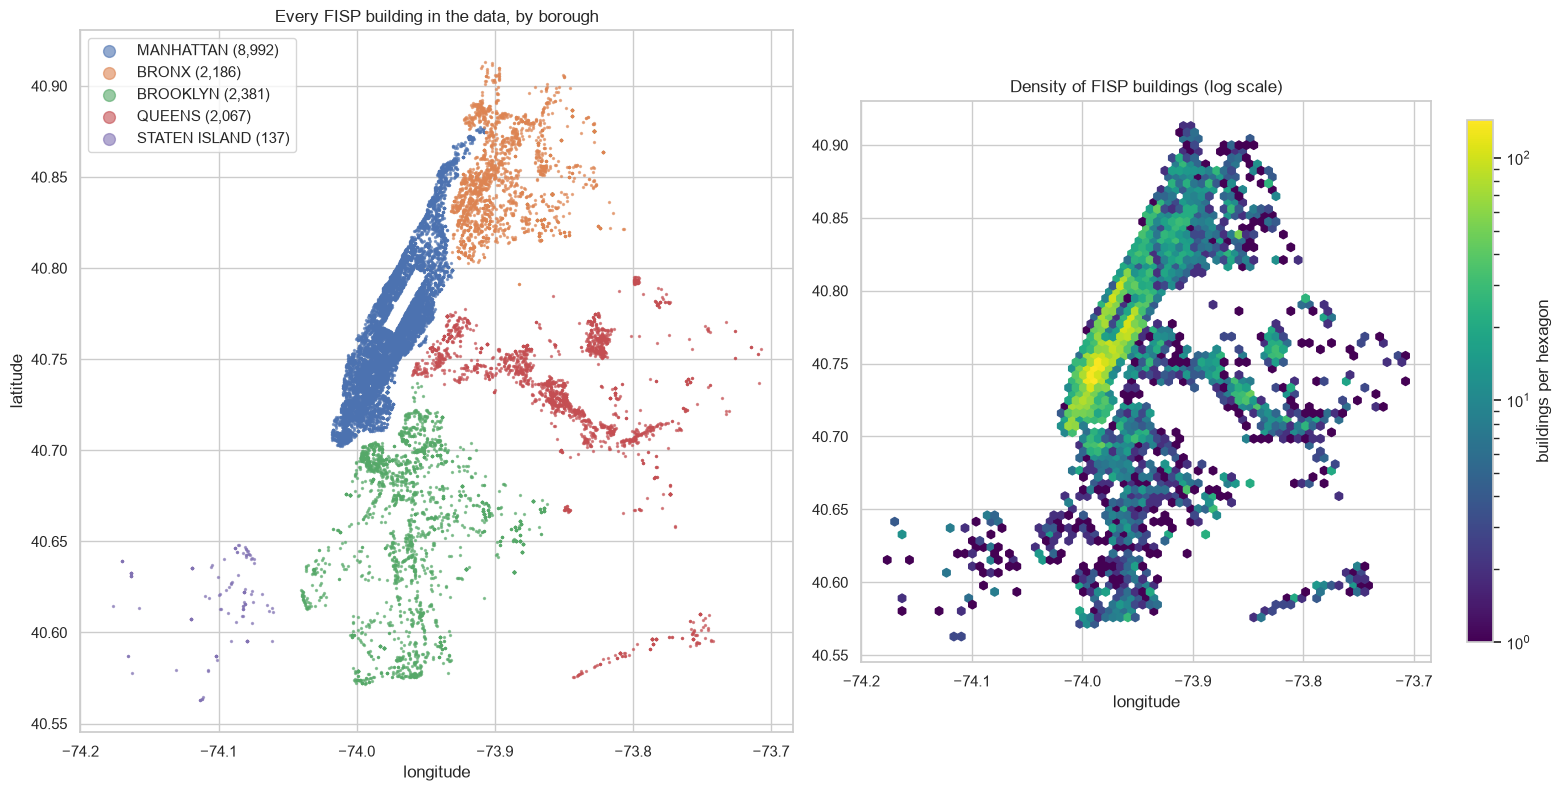

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [1, 1]})

for borough in BOROUGH_ORDER:
    rows = buildings[buildings["BOROUGH"] == borough]
    axes[0].scatter(rows["longitude"], rows["latitude"], s=2, alpha=0.6, label=f"{borough} ({len(rows):,})")
axes[0].set(title="Every FISP building in the data, by borough", xlabel="longitude", ylabel="latitude")
axes[0].set_aspect(1 / np.cos(np.radians(40.7)))
axes[0].legend(markerscale=6, loc="upper left")

hb = axes[1].hexbin(buildings["longitude"], buildings["latitude"], gridsize=70, bins="log", cmap="viridis", mincnt=1)
axes[1].set(title="Density of FISP buildings (log scale)", xlabel="longitude")
axes[1].set_aspect(1 / np.cos(np.radians(40.7)))
plt.colorbar(hb, ax=axes[1], label="buildings per hexagon", shrink=0.7)

fig.tight_layout()
fig.savefig(FIG_DIR / "02_map_fisp_buildings.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# Two maps of every FISP building (longitude on x, latitude on y):
# left = one colour per borough; right = hexbin density (how many buildings per hexagon, log scale).
# set_aspect corrects the map so New York is not stretched (1 degree of longitude is shorter than 1 degree of latitude at 40.7 N).

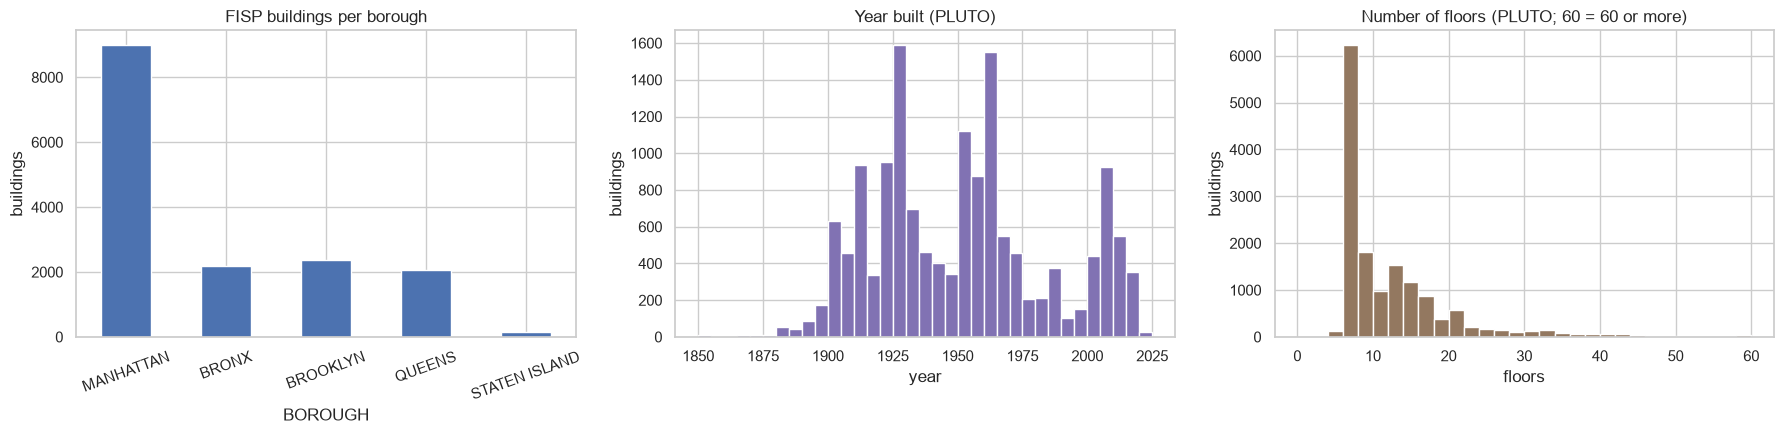

,year_built,num_floors
count,15135.0,15138.0
mean,1950.5,12.0
std,34.4,8.5
min,1824.0,4.0
25%,1925.0,6.0
50%,1950.0,9.0
75%,1970.0,14.0
max,2025.0,102.0


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

buildings["BOROUGH"].value_counts().reindex(BOROUGH_ORDER).plot.bar(ax=axes[0], color="#4C72B0", rot=20)
axes[0].set(title="FISP buildings per borough", ylabel="buildings")

axes[1].hist(buildings["year_built"].dropna(), bins=np.arange(1850, 2030, 5), color="#8172B3")
axes[1].set(title="Year built (PLUTO)", xlabel="year", ylabel="buildings")

axes[2].hist(buildings["num_floors"].dropna().clip(upper=60), bins=np.arange(0, 62, 2), color="#937860")
axes[2].set(title="Number of floors (PLUTO; 60 = 60 or more)", xlabel="floors", ylabel="buildings")

fig.tight_layout()
fig.savefig(FIG_DIR / "03_stock_overview.png", dpi=150, bbox_inches="tight")
plt.show()
buildings[["year_built", "num_floors"]].describe().round(1)

# ---- What this cell does ----
# Three charts of the building stock: buildings per borough, year built and number of floors (from PLUTO).
# clip(upper=60) puts the very tall towers in the last bar so the chart stays readable.
# describe() prints the statistics (median year 1950, median 9 floors).

**The FISP stock** is a city of tall, old, Manhattan buildings: **57% are in Manhattan**, the median building was **built in 1950** (a quarter before
1925, a quarter after 1970) and has **9 floors** (a few towers go above 60). The maps show the dense spine of Manhattan, then the Bronx, the waterfronts
of Brooklyn and Queens, and very few buildings on Staten Island. This is the context for every cluster below: a "Manhattan-heavy" cluster is only
remarkable if it is clearly above 57%.

## 1. Features and preprocessing

### 1.1 Building-level features

From the aggregated table we derive the features that describe each building on a comparable scale:

| Feature | How | Meaning |
|---|---|---|
| `share_unsafe`, `share_swarmp` | UNSAFE (SWARMP) initial filings ÷ all initial filings (a few buildings file more than one initial report in a cycle, e.g. one per facade) | how often the facade was UNSAFE / needed repairs, independent of how long the building was in the programme |
| `ever_unsafe` | 1 if at least one UNSAFE filing | |
| `followups_per_cycle` | AMENDED + SUBSEQUENT filings ÷ `n_cycles` | how much repair paperwork the facade generates |
| `log_penalty` | `log10(total_penalty + 1)` | penalties on a readable scale |
| `n_materials`, `n_wall_types` | number of materials / wall types listed | how mixed the facade is |

In [10]:
n_initial = buildings[["n_safe", "n_swarmp", "n_unsafe"]].sum(axis=1)
buildings["share_unsafe"] = buildings["n_unsafe"] / n_initial
buildings["share_swarmp"] = buildings["n_swarmp"] / n_initial
print("Buildings with more than one initial filing in a cycle:", (n_initial > buildings["n_cycles"]).sum())
buildings["ever_unsafe"] = (buildings["n_unsafe"] > 0).astype(int)
buildings["followups_per_cycle"] = buildings["n_followups"] / buildings["n_cycles"]
buildings["log_penalty"] = np.log10(buildings["total_penalty"] + 1)
buildings["n_materials"] = buildings[MATERIALS].drop(columns="MATERIAL_OTHER").sum(axis=1)
buildings["n_wall_types"] = buildings[WALL_TYPES].drop(columns="WALL_TYPE_OTHER").sum(axis=1)
buildings[["share_unsafe", "share_swarmp", "followups_per_cycle", "log_penalty", "n_materials", "n_wall_types"]].describe().round(2)

# ---- What this cell does ----
# Engineered features (new columns):
# - share_unsafe / share_swarmp: UNSAFE / SWARMP reports divided by ALL initial reports, so the value is always 0-1;
# - ever_unsafe: 1 if the building was UNSAFE at least once;
# - followups_per_cycle: follow-up filings divided by the number of cycles;
# - log_penalty: log10(penalty + 1), because penalties go from 0 to 22 million USD (the +1 avoids log(0));
# - n_materials / n_wall_types: how many materials / wall types are listed ("other" not counted).

Buildings with more than one initial filing in a cycle: 546


,share_unsafe,share_swarmp,followups_per_cycle,log_penalty,n_materials,n_wall_types
count,15763.00,15763.0,15763.00,15763.00,15763.00,15763.00
mean,0.23,0.4,0.25,3.40,1.90,1.92
std,0.29,0.3,0.36,2.24,1.06,0.96
min,0.00,0.0,0.00,0.00,0.00,0.00
25%,0.00,0.2,0.00,0.00,1.00,1.00
50%,0.00,0.4,0.20,4.45,2.00,2.00
75%,0.33,0.6,0.40,5.11,3.00,3.00
max,1.00,1.0,7.00,7.36,7.00,6.00


### 1.2 Which features define "similar"?

Choosing the columns is choosing the meaning of the clusters. For our use case (one programme per *type* of facade), two buildings are
similar when **their facades are made of the same things** and **they have behaved alike in inspections**. We cluster on **13 features**:

- **Inspection record (4):** `share_unsafe`, `share_swarmp`, `followups_per_cycle`, `log_penalty`.
- **Time in the programme (1):** `n_cycles`.
- **Facade materials (8):** `n_materials` and the 0/1 flags for masonry, terra cotta, natural stone, concrete, stucco / EIFS, glass and metal.

**Kept aside for interpretation** (never clustered on), to test whether the groups mean something:

| Variable | Why keep it aside |
|---|---|
| `year_built`, `num_floors` (PLUTO) | If a "terra cotta + stone" group turns out to be pre-1930 *without having seen the year*, the name is earned |
| `latitude`, `longitude`, `BOROUGH` | The maps: do the groups have a geography? |
| `WALL_TYPE_*` | The structural wall system (load-bearing, cavity, steel frame...), a second, independent description of the construction |
| `first_cycle` | When the building entered FISP (newer or newly-tall buildings enter later) |
| `latest_status`, `ever_unsafe`, penalty components | Where the building stands today |

**Left out entirely:** `MATERIAL_OTHER` (a catch-all box on the form that says nothing about the facade) and the raw counts (`n_unsafe`, ...), which
repeat `n_cycles` × share.

In [11]:
FEATURES = [
    "share_unsafe", "share_swarmp", "followups_per_cycle", "log_penalty", "n_cycles", "n_materials",
    "MATERIAL_MASONRY", "MATERIAL_TERRA_COTTA", "MATERIAL_NATURAL_STONE", "MATERIAL_CONCRETE",
    "MATERIAL_STUCCO_EIFS", "MATERIAL_GLASS", "MATERIAL_METAL",
]
NUMERIC = FEATURES[:6]
FLAGS = FEATURES[6:]
X = buildings[FEATURES].astype(float)
print(X.shape)

# ---- What this cell does ----
# The 13 features we cluster on (they define what "similar" means): 6 numeric features about the inspection record and
# the facade, plus 7 material flags (0/1). X is the table the models will use; NUMERIC and FLAGS are used for the charts.

(15763, 13)


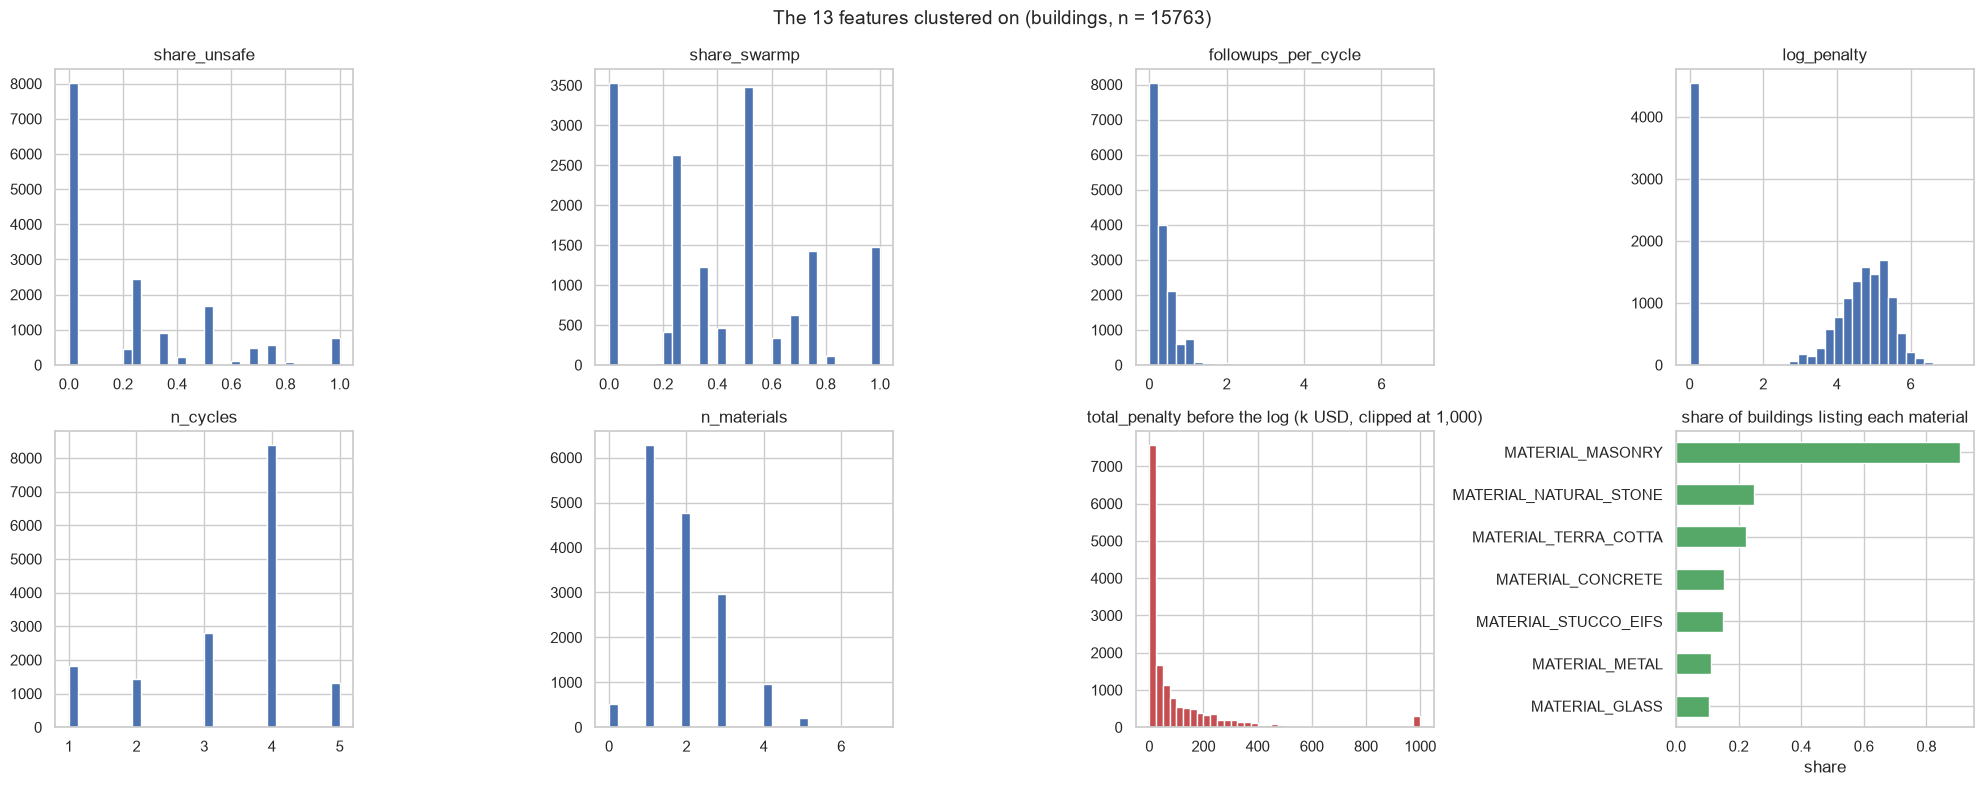

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), NUMERIC):
    ax.hist(X[col], bins=30, color="#4C72B0")
    ax.set_title(col)
ax = axes.ravel()[6]
ax.hist(buildings["total_penalty"].clip(upper=1e6) / 1000, bins=40, color="#C44E52")
ax.set(title="total_penalty before the log (k USD, clipped at 1,000)")
ax = axes.ravel()[7]
X[FLAGS].mean().sort_values().plot.barh(ax=ax, color="#55A868")
ax.set(title="share of buildings listing each material", xlabel="share")
fig.suptitle("The 13 features clustered on (buildings, n = %d)" % len(X), fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# Histograms of the 6 numeric features, the raw penalties (to show why we use the log) and the share of buildings that
# list each material. We look for skewed distributions and very rare values before scaling.

- **Half the buildings (51%) were never UNSAFE** (`share_unsafe` = 0), and a long tail reaches 1 (UNSAFE at every inspection).
- **Most buildings were inspected in 4 cycles** (53%); 12% only once (newer or newly-tall buildings).
- `followups_per_cycle` is 0 for most buildings, with a tail up to 1.5 (99th percentile).
- **Penalties**: 29% of buildings never paid one (`log_penalty` = 0); the others typically paid 10,000–100,000 USD (4–5 on the log scale).
  The raw histogram (bottom middle) shows why the log is needed.
- **Masonry** is listed by 91% of buildings; each of the other materials by 11–25%. Those rarer flags are what will separate the groups.

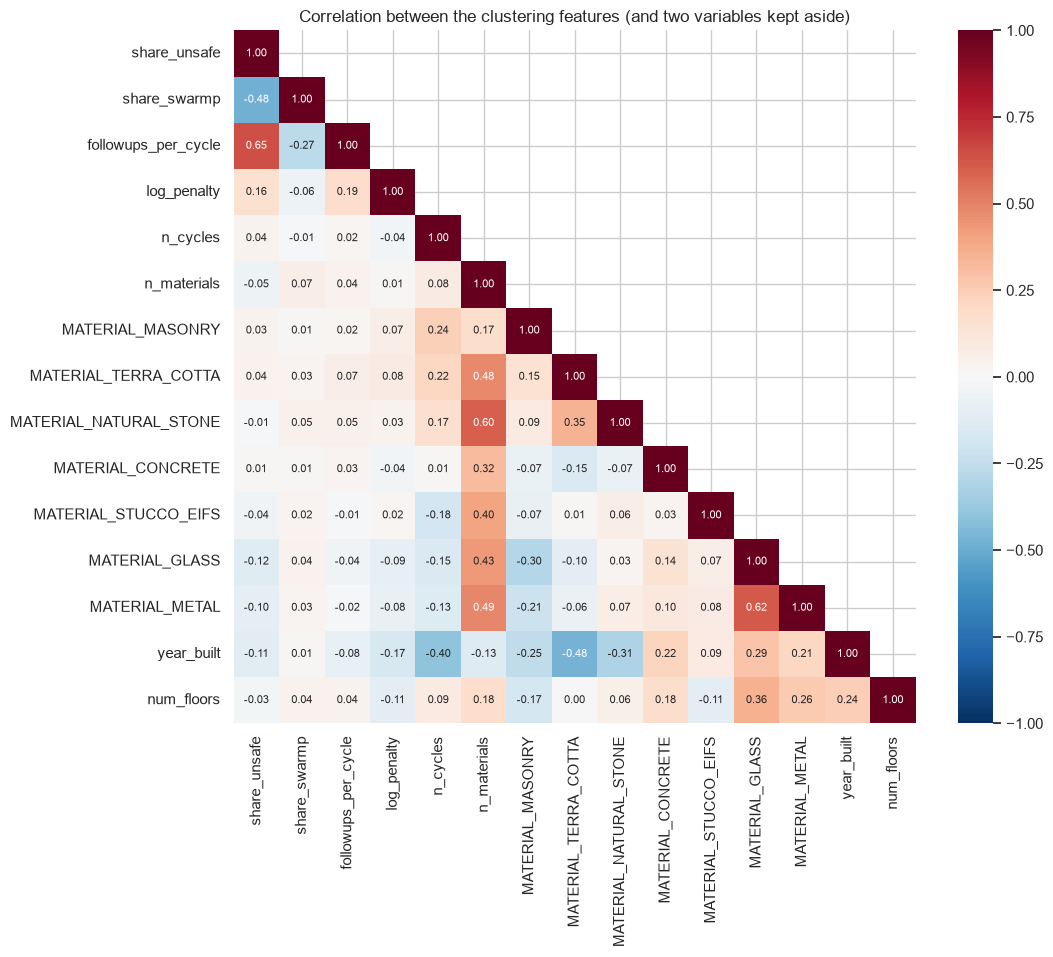

In [13]:
fig, ax = plt.subplots(figsize=(11, 9))
corr = buildings[FEATURES + ["year_built", "num_floors"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation between the clustering features (and two variables kept aside)")
fig.savefig(FIG_DIR / "05_feature_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# Correlation heatmap of the 13 features plus year built and floors (kept aside).
# mask hides the upper half (it repeats the lower half). Values near +1 / -1 = two features move together.
# We check that no two features are almost identical (> 0.8), which would count the same thing twice.

The strongest correlations are expected and help to read the clusters later:

- `share_unsafe` ↔ `followups_per_cycle` (**0.65**): an UNSAFE facade generates amended and follow-up filings (repairs, re-inspections).
- `MATERIAL_GLASS` ↔ `MATERIAL_METAL` (**0.62**): they come together, as curtain walls.
- `share_unsafe` ↔ `share_swarmp` (**−0.48**): the two shares compete for the same inspections.
- With the variables kept aside: **terra cotta goes with older buildings** (−0.48 with year built), **glass with taller ones** (0.36 with floors),
  and buildings in more cycles are older (−0.40). These are hints that the material groups will carry an age signal, without us using the age.

No pair is so correlated (> 0.8) that one feature should be dropped.

### 1.3 Scaling and transformations

- The features do **not** share a unit (shares in 0–1, counts, log-dollars, 0/1 flags), so we standardise them with a `StandardScaler`, inside a
  `Pipeline` for the final model. Without scaling, `n_cycles` (1–5) and `log_penalty` (0–7) would dominate the distances.
- Penalties are extremely skewed, so we use `log10(total + 1)` (see the histograms above).
- `BOROUGH` is categorical and is kept aside for interpretation rather than one-hot encoded.

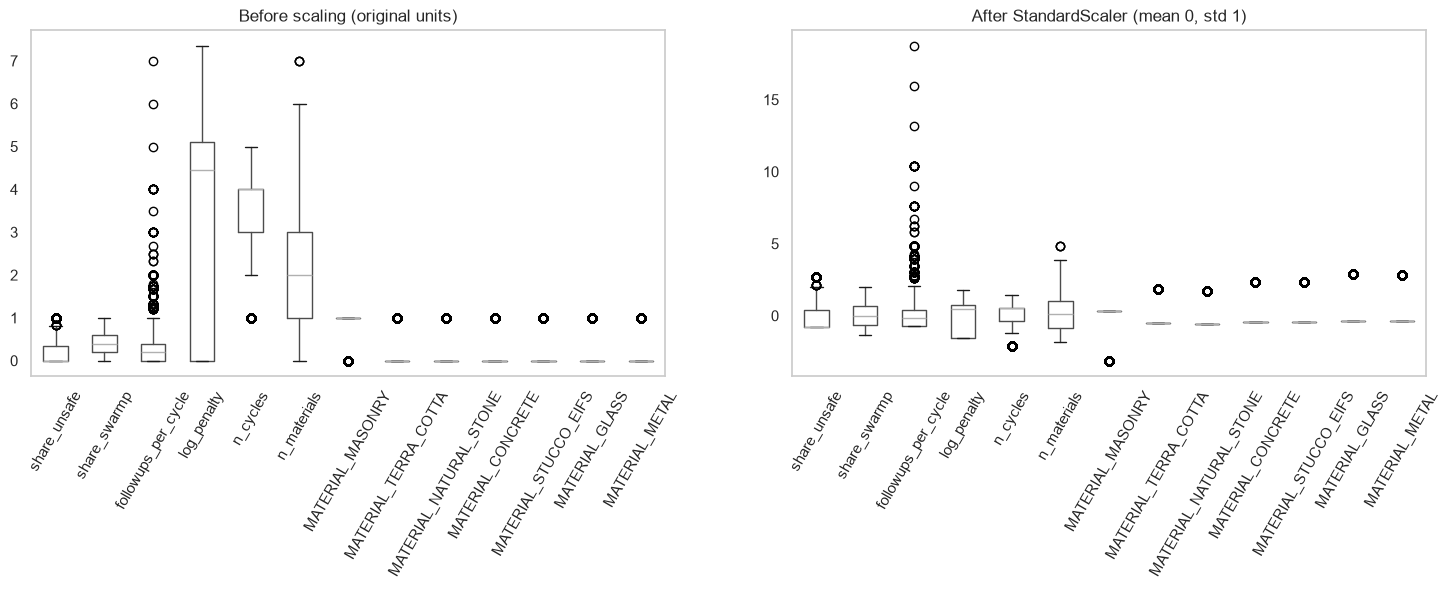

In [14]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))
X.boxplot(ax=axes[0], rot=60, grid=False)
axes[0].set_title("Before scaling (original units)")
pd.DataFrame(X_scaled, columns=FEATURES).boxplot(ax=axes[1], rot=60, grid=False)
axes[1].set_title("After StandardScaler (mean 0, std 1)")
fig.savefig(FIG_DIR / "06_scaling.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# StandardScaler: every feature gets mean 0 and standard deviation 1, so no feature dominates the distances only because
# of its unit (e.g. n_cycles 1-5 vs shares 0-1). The two boxplots show the features before and after scaling.

## 2. Dimensionality reduction

### 2.1 PCA: how many real dimensions?

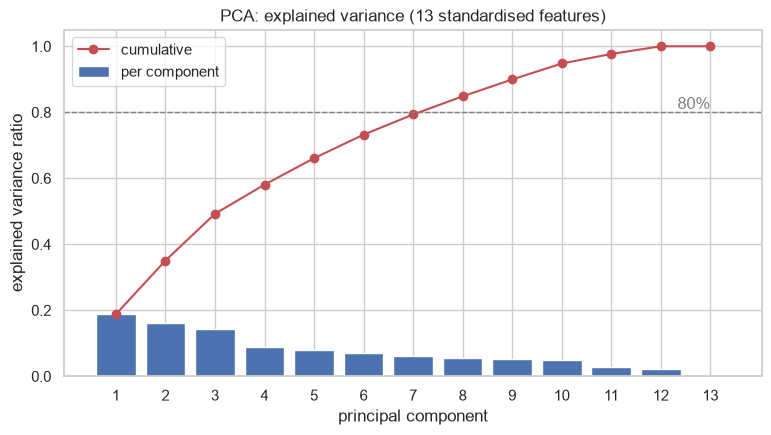

Explained variance: [0.188 0.162 0.142 0.088 0.08  0.071 0.061 0.055 0.051 0.048 0.029 0.023
 0.   ]
Cumulative: [0.188 0.351 0.492 0.581 0.661 0.732 0.793 0.848 0.899 0.948 0.977 1.
 1.   ]
Components needed for 80%: 8


In [15]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
evr = pca_full.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(range(1, len(evr) + 1), evr, color="#4C72B0", label="per component")
ax.plot(range(1, len(evr) + 1), evr.cumsum(), "o-", color="#C44E52", label="cumulative")
ax.axhline(0.8, ls="--", color="grey", lw=1)
ax.text(len(evr), 0.81, "80%", ha="right", color="grey")
ax.set(xlabel="principal component", ylabel="explained variance ratio", title="PCA: explained variance (13 standardised features)")
ax.set_xticks(range(1, len(evr) + 1))
ax.legend()
fig.savefig(FIG_DIR / "07_pca_explained_variance.png", dpi=150, bbox_inches="tight")
plt.show()
print("Explained variance:", evr.round(3))
print("Cumulative:", evr.cumsum().round(3))
print("Components needed for 80%:", int(np.argmax(evr.cumsum() >= 0.8)) + 1)

# ---- What this cell does ----
# PCA with all 13 components. explained_variance_ratio_ = how much of the total variation each component keeps.
# Bars = per component, red line = cumulative. We print how many components are needed for 80% (8): the data has many
# dimensions, no single dominant direction.

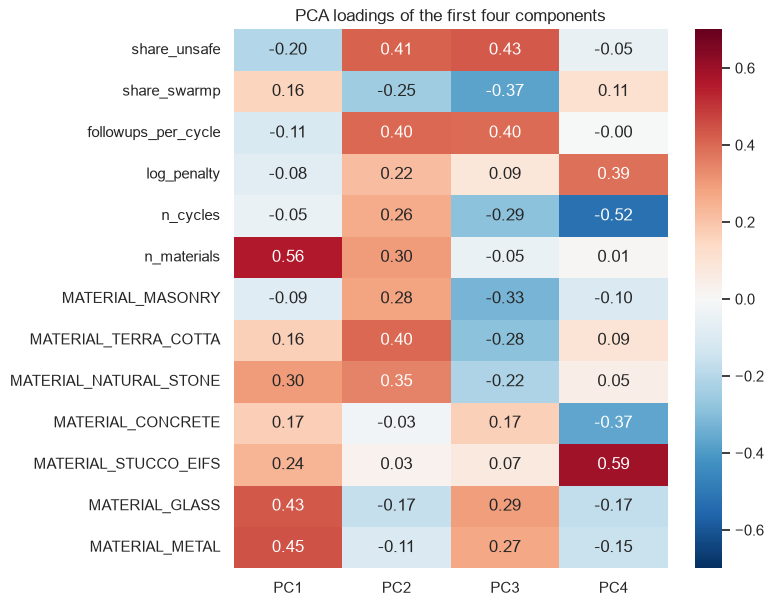

In [16]:
loadings = pd.DataFrame(pca_full.components_[:4].T, index=FEATURES, columns=["PC1", "PC2", "PC3", "PC4"])
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.7, vmax=0.7, ax=ax)
ax.set_title("PCA loadings of the first four components")
fig.savefig(FIG_DIR / "08_pca_loadings.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# Loadings of the first 4 principal components: how much each feature contributes to each component
# (red = positive, blue = negative). We read them to give each component a meaning (see the markdown below).

**How many real dimensions?** The variance is spread out: PC1 explains **19%**, PC2 **16%**, PC3 **14%**, and **8 components** are needed to reach
80%. There is no single dominant direction; the data is genuinely multi-dimensional, which already warns us that clusters will overlap.

**Reading the loadings** (sign is arbitrary):

- **PC1 (19%): "how many materials, and modern ones".** Large positive loadings for `n_materials` (0.57), metal (0.45), glass (0.43) and stone (0.30).
  High PC1 = mixed facades with glass and metal; low PC1 = single-material brick.
- **PC2 (16%): "troubled old masonry".** Positive for `share_unsafe` and `followups_per_cycle` (0.41 each), terra cotta (0.40), stone (0.35), masonry
  and n_cycles; negative for glass. It mixes risk with *traditional* materials: the old ornamented facades are both long in the programme and more often in trouble.
- **PC3 (14%): "risk without ornament".** Again `share_unsafe` and `followups_per_cycle` (0.44, 0.41), but now *against* terra cotta, stone, masonry and SWARMP.
  PC2 and PC3 together separate "risky because old and ornamented" from "risky whatever the material".
- **PC4 (9%): "stucco vs concrete, and newcomers".** Stucco / EIFS (0.59) and penalties against concrete and `n_cycles` (−0.52).

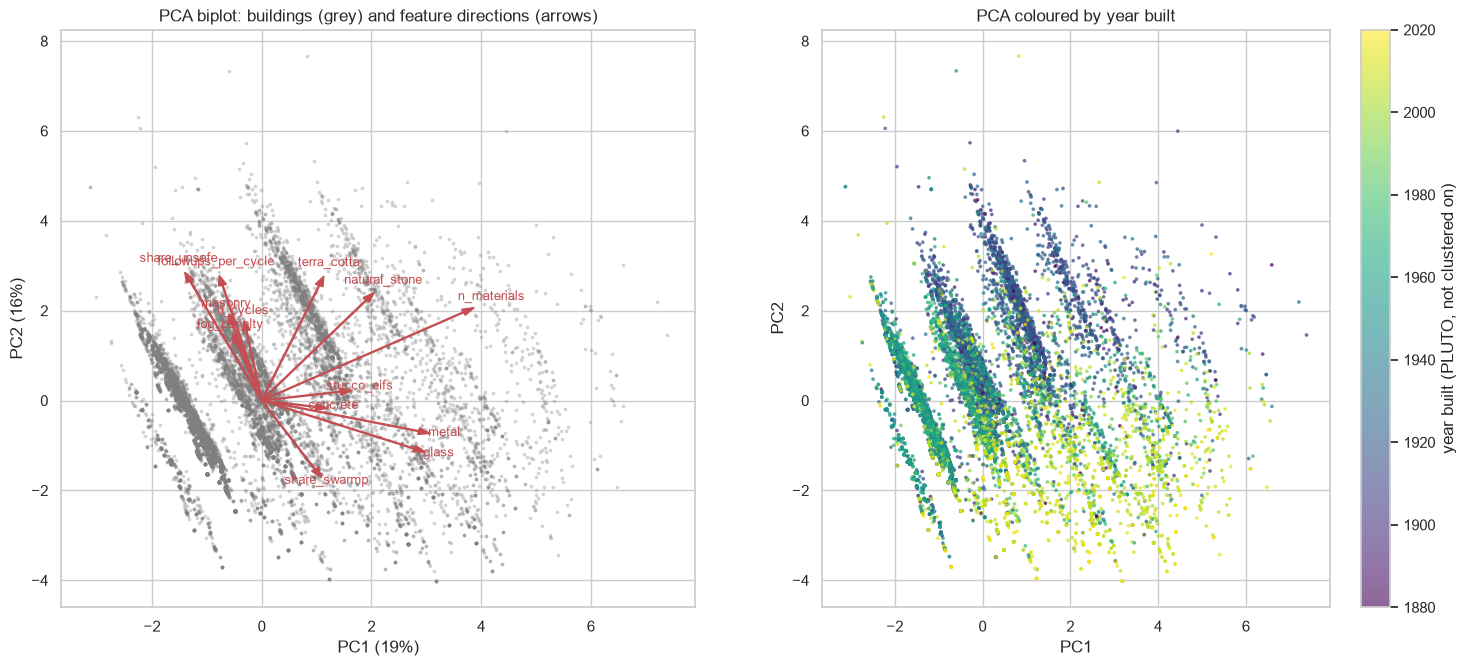

In [17]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
pca_xy = pca2.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
axes[0].scatter(pca_xy[:, 0], pca_xy[:, 1], s=3, alpha=0.25, color="grey")
scale = np.abs(pca_xy).max() * 0.9
for feat, (lx, ly) in zip(FEATURES, pca2.components_.T):
    axes[0].arrow(0, 0, lx * scale, ly * scale, color="#C44E52", width=0.02, head_width=0.15, length_includes_head=True)
    axes[0].text(lx * scale * 1.08, ly * scale * 1.08, feat.replace("MATERIAL_", "").lower(), fontsize=9, ha="center", color="#C44E52")
axes[0].set(title="PCA biplot: buildings (grey) and feature directions (arrows)", xlabel="PC1 (%.0f%%)" % (100 * evr[0]),
            ylabel="PC2 (%.0f%%)" % (100 * evr[1]))

sc = axes[1].scatter(pca_xy[:, 0], pca_xy[:, 1], s=3, alpha=0.6, c=buildings["year_built"], cmap="viridis", vmin=1880, vmax=2020)
plt.colorbar(sc, ax=axes[1], label="year built (PLUTO, not clustered on)")
axes[1].set(title="PCA coloured by year built", xlabel="PC1", ylabel="PC2")
fig.savefig(FIG_DIR / "09_pca_biplot.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# PCA with 2 components = the 2D coordinates of every building (pca_xy, exported later as pca_x / pca_y).
# Left: biplot = buildings in grey + one arrow per feature showing its direction on the map.
# Right: the same points coloured by year built, which the PCA never saw, to check whether the map carries an age signal.

The biplot shows the same story: the glass and metal arrows point one way, terra cotta and stone another, and the two risk arrows (`share_unsafe`,
`followups_per_cycle`) a third. The right panel colours the same points by **year built, which the PCA never saw**: the older buildings sit in the
upper part of the cloud (PC2 has a correlation of **−0.48** with the year built in the exported coordinates). The material features carry an age signal.

### 2.2 t-SNE

We use **t-SNE** (scikit-learn) to draw the buildings in 2D. We chose t-SNE over UMAP to avoid an extra dependency (umap-learn and numba) in
our Python 3.14 environment. Perplexity 50 suits a dataset of this size. **Remember:** t-SNE keeps neighbourhoods, but the **sizes of the islands
and the distances between them mean nothing**.

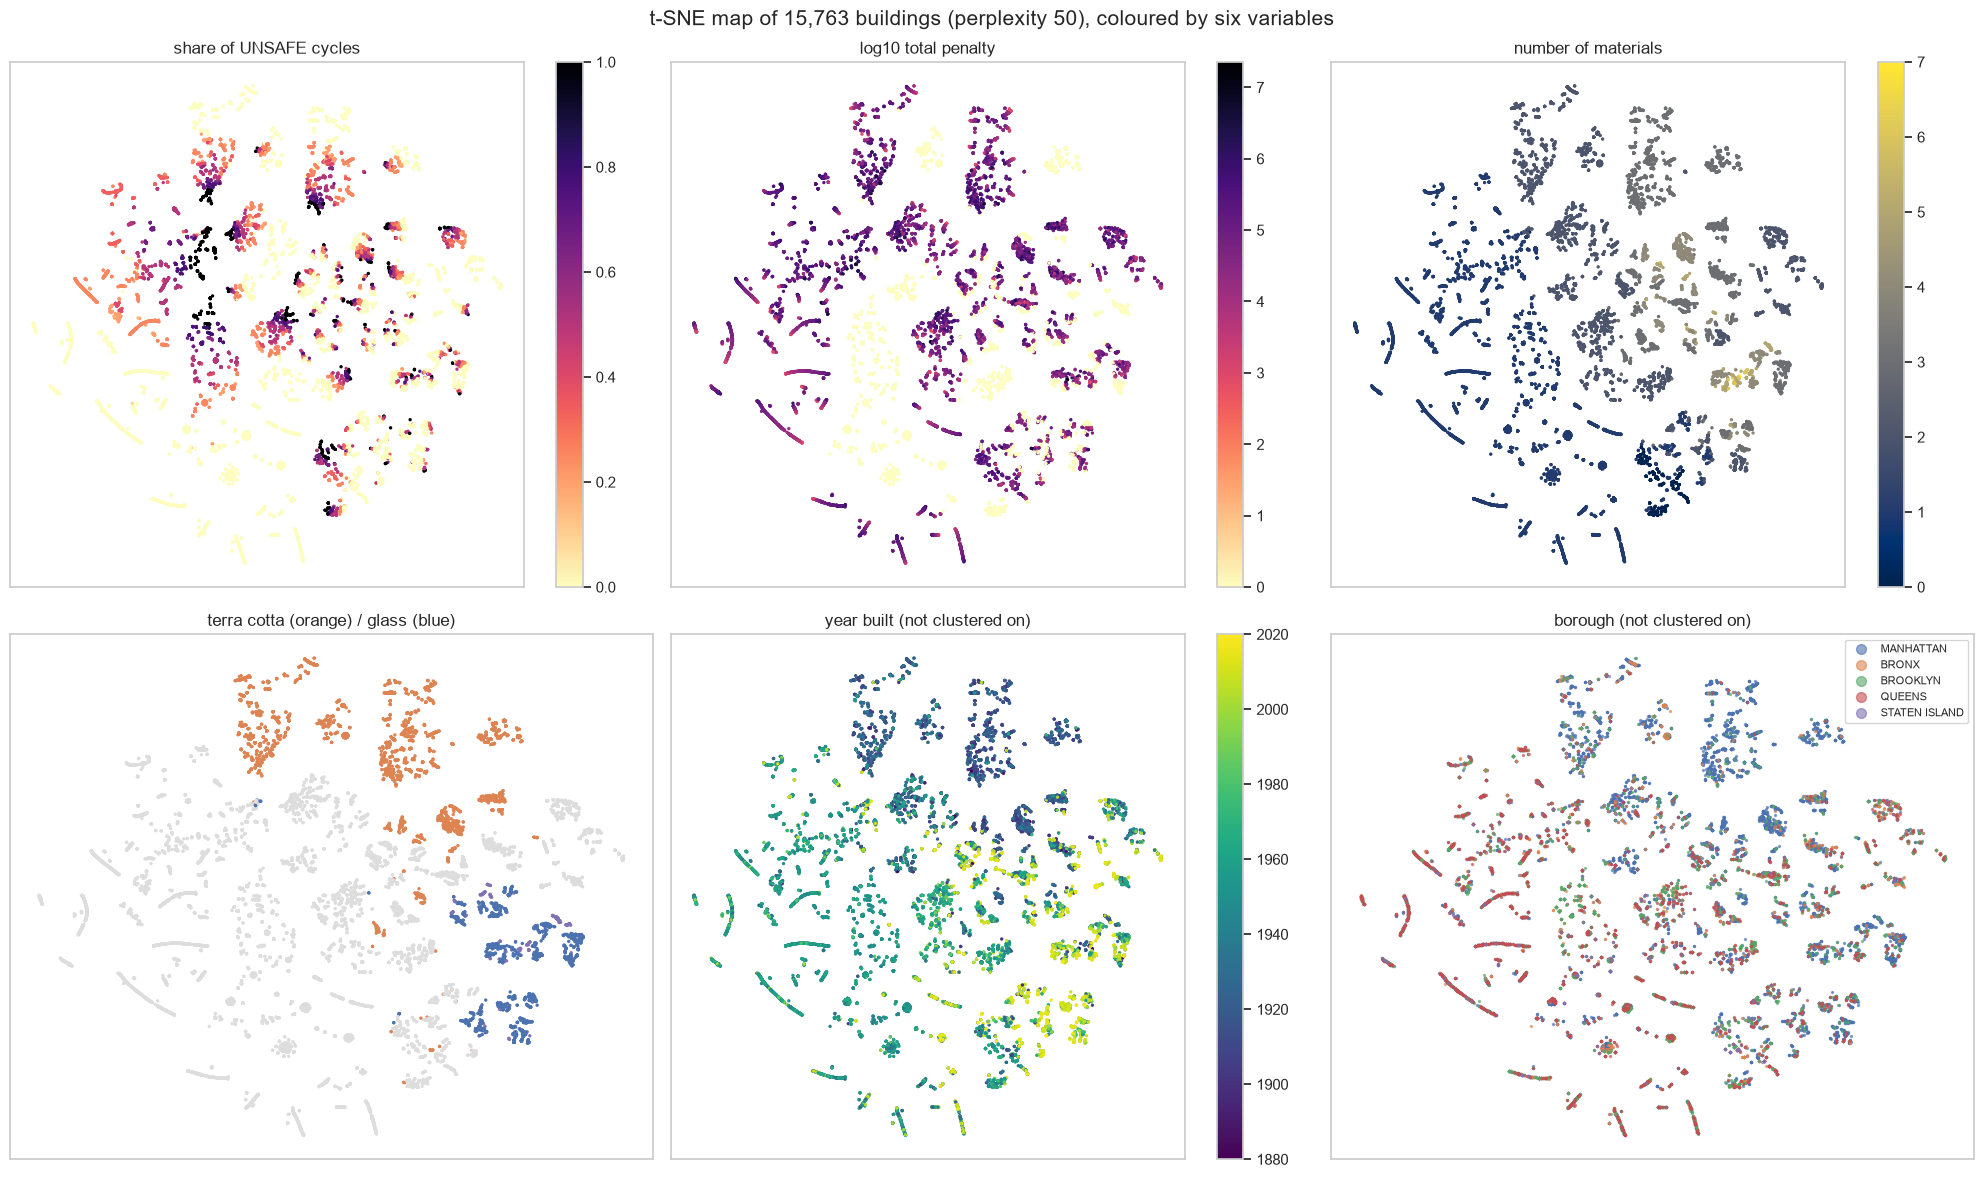

In [18]:
tsne = TSNE(n_components=2, perplexity=50, init="pca", random_state=RANDOM_STATE)
tsne_xy = tsne.fit_transform(X_scaled)

def tsne_panel(ax, values, title, cmap="viridis", **kw):
    sc = ax.scatter(tsne_xy[:, 0], tsne_xy[:, 1], s=2, c=values, cmap=cmap, **kw)
    ax.set(title=title, xticks=[], yticks=[])
    return sc

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
plt.colorbar(tsne_panel(axes[0, 0], buildings["share_unsafe"], "share of UNSAFE cycles", "magma_r"), ax=axes[0, 0])
plt.colorbar(tsne_panel(axes[0, 1], buildings["log_penalty"], "log10 total penalty", "magma_r"), ax=axes[0, 1])
plt.colorbar(tsne_panel(axes[0, 2], buildings["n_materials"], "number of materials", "cividis"), ax=axes[0, 2])
tsne_panel(axes[1, 0], buildings["MATERIAL_TERRA_COTTA"] + 2 * buildings["MATERIAL_GLASS"], "terra cotta (orange) / glass (blue)",
           cmap=plt.matplotlib.colors.ListedColormap(["#dddddd", "#DD8452", "#4C72B0", "#8172B3"]), vmin=0, vmax=3)
plt.colorbar(tsne_panel(axes[1, 1], buildings["year_built"], "year built (not clustered on)", vmin=1880, vmax=2020), ax=axes[1, 1])
for borough in BOROUGH_ORDER:
    m = (buildings["BOROUGH"] == borough).to_numpy()
    axes[1, 2].scatter(tsne_xy[m, 0], tsne_xy[m, 1], s=2, alpha=0.6, label=borough)
axes[1, 2].set(title="borough (not clustered on)", xticks=[], yticks=[])
axes[1, 2].legend(markerscale=5, fontsize=8)
fig.suptitle("t-SNE map of 15,763 buildings (perplexity 50), coloured by six variables", fontsize=15)
fig.tight_layout()
fig.savefig(FIG_DIR / "10_tsne_coloured.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# t-SNE: a non-linear 2D map that keeps neighbours together (tsne_xy, exported as tsne_x / tsne_y).
# perplexity=50 ~ how many neighbours each point considers; init="pca" and random_state make it reproducible.
# tsne_panel() is a small helper that draws the map coloured by one variable. We colour it by 6 variables
# (risk, penalties, number of materials, terra cotta / glass, year built, borough) to understand what the islands are.

**What the t-SNE map shows** (keeping in mind that island sizes and distances mean nothing):

- The map breaks into **many small islands**. That is mostly the 0/1 material flags: buildings with exactly the same combination of materials end up
  together. The real structure is **groups of islands**, not single islands.
- **Terra cotta (orange) occupies the top** of the map and **glass (blue) the right side**: two clearly separated regions.
- The **year-built panel** (not clustered on) matches: the terra-cotta region is dark (pre-1930), the glass region is yellow (after 1980).
- **Risk** (`share_unsafe`, top-left) is not one region; it appears inside **almost every island**, as a red "edge" of the material groups. Risk cuts
  across the materials rather than forming its own neighbourhood.
- **Boroughs** are mixed everywhere except the terra-cotta and glass regions, which are mostly Manhattan.

**Does the picture depend on the perplexity?** We redraw t-SNE on a 4,000-building sample with three perplexities. If the islands only
appear at one setting, they would be an artefact.

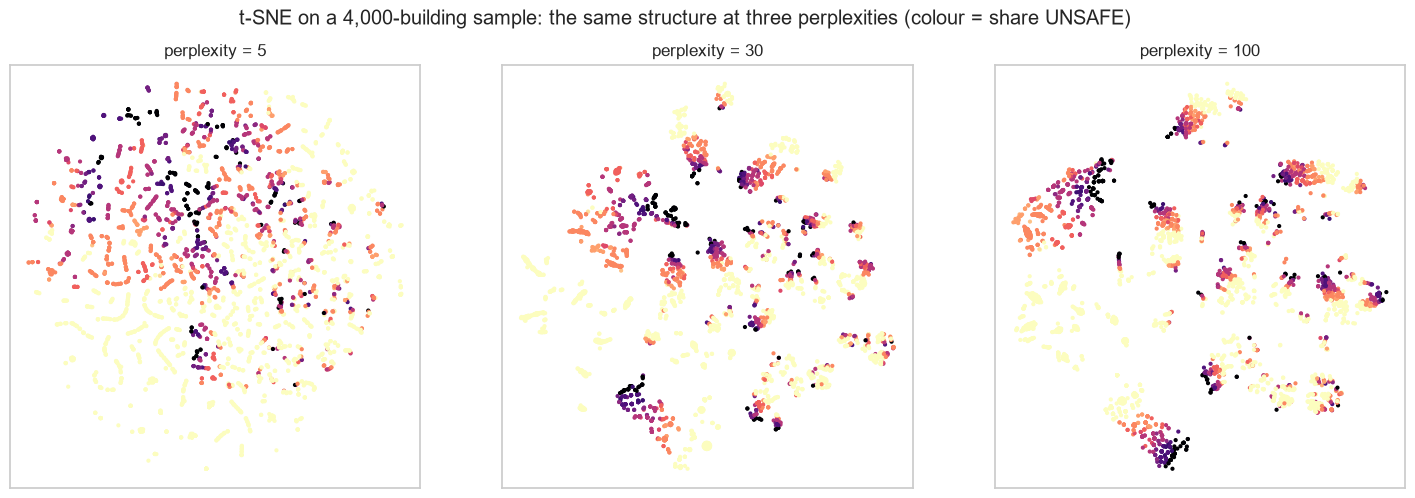

In [19]:
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(X_scaled), size=4000, replace=False)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, perp in zip(axes, [5, 30, 100]):
    xy = TSNE(n_components=2, perplexity=perp, init="pca", random_state=RANDOM_STATE).fit_transform(X_scaled[sample_idx])
    ax.scatter(xy[:, 0], xy[:, 1], s=4, c=buildings["share_unsafe"].to_numpy()[sample_idx], cmap="magma_r")
    ax.set(title=f"perplexity = {perp}", xticks=[], yticks=[])
fig.suptitle("t-SNE on a 4,000-building sample: the same structure at three perplexities (colour = share UNSAFE)")
fig.savefig(FIG_DIR / "11_tsne_perplexity.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# Robustness check of t-SNE: we redraw it on a random sample of 4,000 buildings with three perplexities (5, 30, 100).
# If the same structure appears at each setting, it is real and not an artefact of one parameter.
# sample_idx is reused later for the dendrogram and the silhouette plot.

At perplexity 5 the map is a cloud of fragments; at 30 and 100 the same groups of islands appear, with the safe buildings (pale) on one side and
UNSAFE-heavy groups (dark) gathered in a few places. The large-scale structure does not depend on the perplexity, so it is not an artefact of t-SNE.

## 3. Clustering

### 3.1 K-Means: choosing k

We fit K-Means for k = 2 … 12 and plot the inertia (elbow) and the silhouette score (on a fixed random sample of 5,000 buildings, to keep it fast).

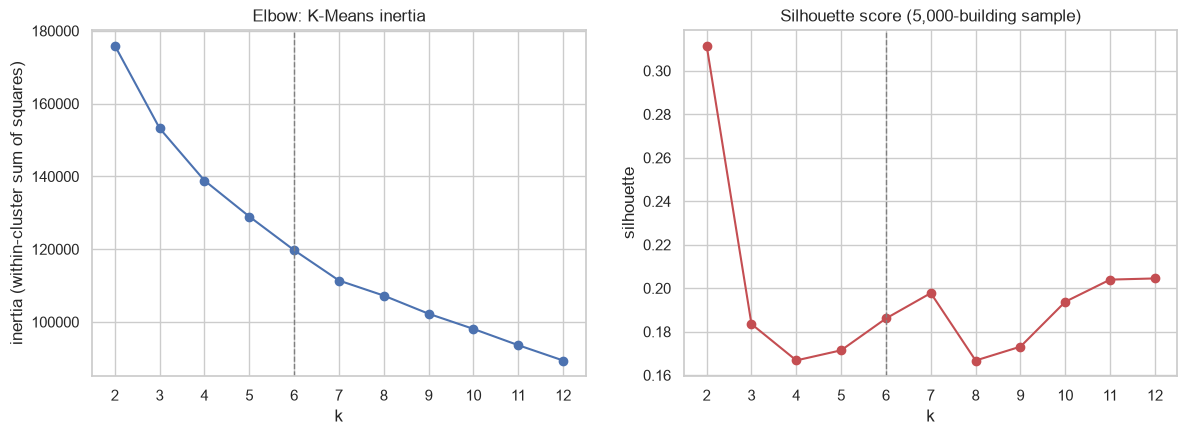

k,2,3,4,5,6,7,8,9,10,11,12
inertia,175968.000,153216.000,138864.000,128970.000,119727.000,111390.000,107244.000,102259.000,98088.000,93619.000,89407.000
silhouette,0.312,0.184,0.167,0.171,0.186,0.198,0.167,0.173,0.194,0.204,0.204


In [20]:
ks = range(2, 13)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_, sample_size=5000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(list(ks), inertias, "o-")
axes[0].set(title="Elbow: K-Means inertia", xlabel="k", ylabel="inertia (within-cluster sum of squares)")
axes[1].plot(list(ks), silhouettes, "o-", color="#C44E52")
axes[1].set(title="Silhouette score (5,000-building sample)", xlabel="k", ylabel="silhouette")
for ax in axes:
    ax.axvline(6, ls="--", color="grey", lw=1)
    ax.set_xticks(list(ks))
fig.savefig(FIG_DIR / "12_choice_of_k.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame({"k": list(ks), "inertia": np.round(inertias), "silhouette": np.round(silhouettes, 3)}).set_index("k").T

# ---- What this cell does ----
# Choosing k for K-Means: we fit K-Means for k = 2 to 12 and store
# - inertia = sum of squared distances to the cluster centres (always decreases; we look for an "elbow");
# - silhouette = how well each building fits its own cluster vs the next one (-1 to 1, higher is better), on 5,000 buildings for speed.
# The dashed line marks our choice, k = 6.

**No k stands out**, which is common with real data:

- The **elbow** curve bends smoothly, with no sharp knee.
- The **silhouette** is highest at **k = 2 (0.31)**, then drops to **0.17–0.20** for every k between 3 and 12. The k = 2 split is not useful for
  our use case: it mostly separates glass-and-metal buildings from the rest.
- Between 3 and 12 the silhouette is flat, so we chose k by **interpretability and stability** (section 4): at **k = 6** every group can be
  named and calls for a different programme, while at k = 5 the small non-masonry group dissolves into the others, and from k = 7 the
  solutions change from one subsample to the next (section 4).

So **k = 6**, with an honest silhouette of about **0.20**: the groups are real tendencies in the data, not well-separated islands.

In [21]:
K = 6
kmeans = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(X_scaled)
labels_km = kmeans.labels_
print("Cluster sizes:", np.bincount(labels_km))
print("Silhouette (all buildings):", round(silhouette_score(X_scaled, labels_km), 3))

# ---- What this cell does ----
# Final K-Means with k = 6. n_init=50 = 50 different random starts, the best one is kept (more stable than the default 10).
# labels_km = the cluster (0-5) of every building. We print the cluster sizes and the silhouette on all buildings (0.20).

Cluster sizes: [1031 6054 3263 1693 2347 1375]


Silhouette (all buildings): 0.203


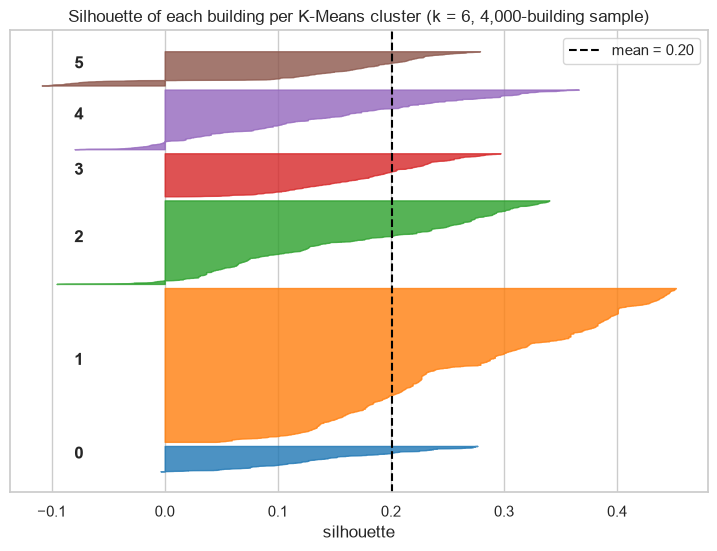

0    0.148
1    0.274
2    0.164
3    0.182
4    0.138
5    0.140
Name: mean silhouette per cluster, dtype: float64


In [22]:
# silhouette of every building, grouped by cluster (on the 4,000-building sample)
sil = silhouette_samples(X_scaled[sample_idx], labels_km[sample_idx])
fig, ax = plt.subplots(figsize=(9, 6))
y = 0
colors = sns.color_palette("tab10", K)
for c in range(K):
    vals = np.sort(sil[labels_km[sample_idx] == c])
    ax.fill_betweenx(np.arange(y, y + len(vals)), 0, vals, color=colors[c], alpha=0.8)
    ax.text(-0.08, y + len(vals) / 2, str(c), fontweight="bold")
    y += len(vals) + 40
ax.axvline(sil.mean(), ls="--", color="black", label=f"mean = {sil.mean():.2f}")
ax.set(title=f"Silhouette of each building per K-Means cluster (k = {K}, 4,000-building sample)", xlabel="silhouette", yticks=[])
ax.legend()
fig.savefig(FIG_DIR / "13_silhouette_per_cluster.png", dpi=150, bbox_inches="tight")
plt.show()
print(pd.Series(sil).groupby(labels_km[sample_idx]).mean().round(3).rename("mean silhouette per cluster"))

# ---- What this cell does ----
# Silhouette of every building, grouped by cluster (on the 4,000-building sample).
# Each coloured shape = one cluster, sorted from best to worst fitting building. Values below 0 = buildings that are closer
# to another cluster. The dashed line is the average. It shows which clusters are solid and which are fuzzy.

The silhouette per building shows that the clusters are **not equally solid**. The large plain-brick group (cluster 1) is the most coherent
(mean 0.27); the glass-and-metal and the repeatedly-unsafe groups (0.14) contain many buildings close to a border (silhouette near or below 0),
which is what we expect from groups defined by *tendencies* (mostly glass, mostly unsafe) rather than by strict rules.

### 3.2 Hierarchical clustering (Ward)

Ward linkage on 15,763 buildings needs a distance matrix of about 1 GB, so we build the **dendrogram on the same random sample of 4,000 buildings**,
cut it into k clusters, and extend the labels to every building with a 5-nearest-neighbour classifier fitted on the sample. That gives a Ward label for
every building, which we compare with K-Means.

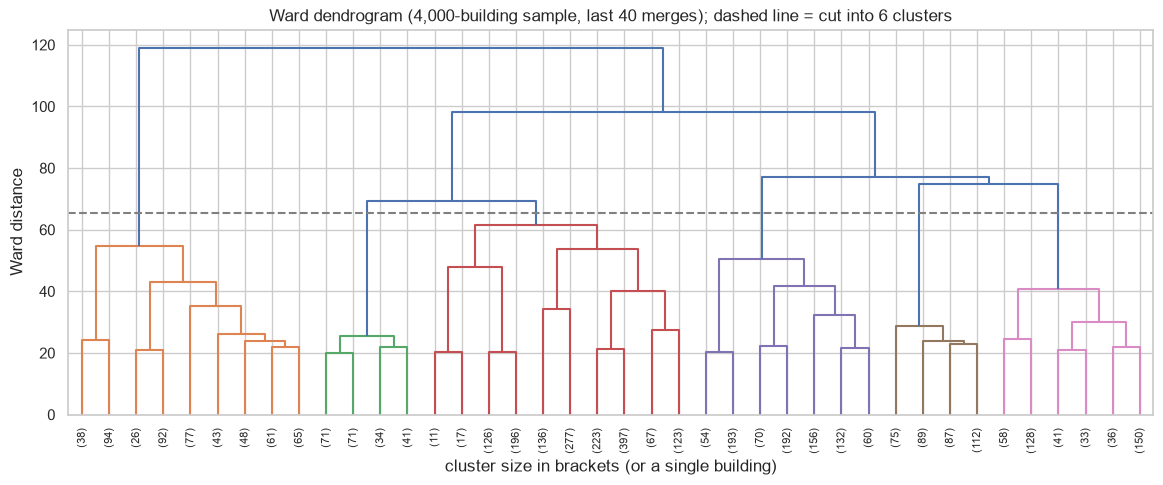

Heights of the last 10 merges: [ 47.9  50.6  53.7  54.8  61.5  69.5  74.9  77.   98.1 119. ]


In [23]:
X_sample = X_scaled[sample_idx]
Z = linkage(X_sample, method="ward")
cut = (Z[-K, 2] + Z[-(K - 1), 2]) / 2
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, truncate_mode="lastp", p=40, ax=ax, color_threshold=cut, leaf_rotation=90)
ax.axhline(cut, ls="--", color="grey")
ax.set(title=f"Ward dendrogram (4,000-building sample, last 40 merges); dashed line = cut into {K} clusters",
       xlabel="cluster size in brackets (or a single building)", ylabel="Ward distance")
fig.savefig(FIG_DIR / "14_ward_dendrogram.png", dpi=150, bbox_inches="tight")
plt.show()
print("Heights of the last 10 merges:", Z[-10:, 2].round(1))

# ---- What this cell does ----
# Hierarchical clustering with Ward linkage (merges the two groups that increase the variance the least, step by step).
# linkage() on 4,000 buildings (all 15,763 would need ~1 GB of memory). The dendrogram shows the last 40 merges;
# the height of a merge = how different the two merged groups are. The dashed line is the cut into 6 clusters.

The dendrogram has **two very high merges at the top** (119 and 98), which match the k = 2 / k = 3 splits, then a series of merges between 48 and
77 with no clear gap. Cutting into 6 groups is therefore a choice inside a continuum, consistent with the flat silhouette curve.

Ward cluster sizes: [6078 2187 1665 3507 1446  880]


Silhouette Ward (all buildings): 0.202
ARI K-Means vs Ward (all buildings): 0.445


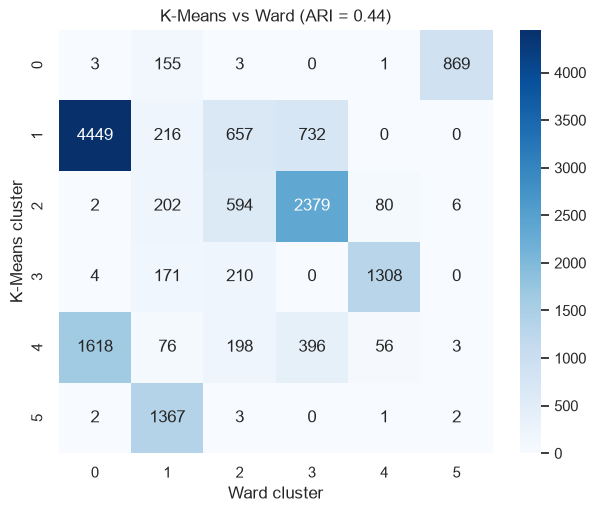

In [24]:
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X_sample)
knn_ward = KNeighborsClassifier(n_neighbors=5).fit(X_sample, ward.labels_)
labels_ward = knn_ward.predict(X_scaled)

print("Ward cluster sizes:", np.bincount(labels_ward))
print("Silhouette Ward (all buildings):", round(silhouette_score(X_scaled, labels_ward), 3))
ari_km_ward = adjusted_rand_score(labels_km, labels_ward)
print("ARI K-Means vs Ward (all buildings):", round(ari_km_ward, 3))

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(pd.crosstab(pd.Series(labels_km, name="K-Means cluster"), pd.Series(labels_ward, name="Ward cluster")),
            annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title(f"K-Means vs Ward (ARI = {ari_km_ward:.2f})")
fig.savefig(FIG_DIR / "15_kmeans_vs_ward.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# Ward clustering into 6 groups on the sample, then a 5-nearest-neighbour classifier gives a Ward label to every building
# (labels_ward, exported as cluster_ward). ARI (adjusted Rand index) compares K-Means and Ward: 1 = identical, 0 = random.
# The heatmap shows which K-Means cluster ends up in which Ward cluster.

**K-Means and Ward agree moderately (ARI = 0.45)**, and the cross-table shows exactly where:

- They **agree on the material groups**: glass & metal (1,367 of 1,375 buildings in the same Ward group), non-masonry (869 of 1,031),
  concrete & brick (1,308 of 1,693) and terra cotta & stone (2,379 of 3,263).
- They **disagree on risk**: Ward puts most of K-Means' "repeatedly unsafe" group (1,618 of 2,347) **inside the plain-brick group**. Ward merges
  by the largest variance first, and the binary material flags dominate; K-Means keeps a separate high-risk group.

### 3.3 DBSCAN: dense cores and noise

As a third view we try DBSCAN. We read `eps` from the k-distance plot (distance to the 10th neighbour, `min_samples = 10`).

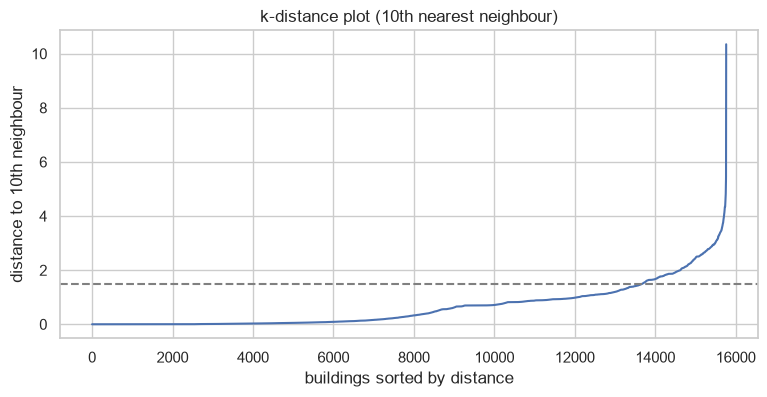

,eps,clusters,noise,largest cluster
0,0.5,255,0.433,0.049
1,1.0,82,0.185,0.257
2,1.5,59,0.087,0.377
3,2.0,53,0.042,0.378


In [25]:
nn = NearestNeighbors(n_neighbors=10).fit(X_scaled)
kdist = np.sort(nn.kneighbors(X_scaled)[0][:, -1])
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(kdist)
ax.axhline(1.5, ls="--", color="grey")
ax.set(title="k-distance plot (10th nearest neighbour)", xlabel="buildings sorted by distance", ylabel="distance to 10th neighbour")
fig.savefig(FIG_DIR / "16_dbscan_kdistance.png", dpi=150, bbox_inches="tight")
plt.show()

rows = []
for eps in (0.5, 1.0, 1.5, 2.0):
    lab = DBSCAN(eps=eps, min_samples=10).fit_predict(X_scaled)
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    rows.append({"eps": eps, "clusters": n_cl, "noise": (lab == -1).mean(),
                 "largest cluster": np.bincount(lab[lab >= 0]).max() / len(lab) if n_cl else 0})
pd.DataFrame(rows).round(3)

# ---- What this cell does ----
# DBSCAN needs eps (radius) and min_samples. The k-distance plot sorts every building by the distance to its 10th
# neighbour; the bend of the curve suggests eps. The table tries 4 values of eps and reports the number of clusters,
# the share of noise (label -1 = buildings in no dense region) and the size of the largest cluster.

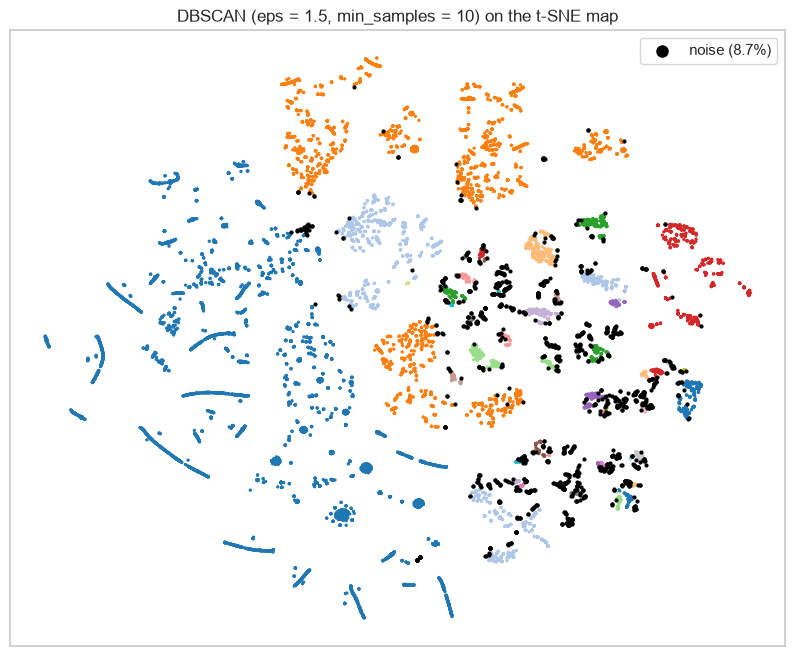

DBSCAN clusters: 59 | ARI with K-Means: 0.421
Noise buildings, mean share UNSAFE: 0.28 (all: 0.23)


In [26]:
labels_db = DBSCAN(eps=1.5, min_samples=10).fit_predict(X_scaled)
fig, ax = plt.subplots(figsize=(10, 8))
noise = labels_db == -1
ax.scatter(tsne_xy[~noise, 0], tsne_xy[~noise, 1], s=2, c=labels_db[~noise], cmap="tab20")
ax.scatter(tsne_xy[noise, 0], tsne_xy[noise, 1], s=4, color="black", label=f"noise ({noise.mean():.1%})")
ax.set(title="DBSCAN (eps = 1.5, min_samples = 10) on the t-SNE map", xticks=[], yticks=[])
ax.legend(markerscale=4)
fig.savefig(FIG_DIR / "17_dbscan_tsne.png", dpi=150, bbox_inches="tight")
plt.show()
print("DBSCAN clusters:", len(set(labels_db)) - 1, "| ARI with K-Means:", round(adjusted_rand_score(labels_km, labels_db), 3))
print("Noise buildings, mean share UNSAFE: %.2f (all: %.2f)" % (buildings.loc[noise, "share_unsafe"].mean(), buildings["share_unsafe"].mean()))

# ---- What this cell does ----
# DBSCAN with eps = 1.5 drawn on the t-SNE map: colours = DBSCAN clusters, black = noise.
# We print its ARI with K-Means and check whether the noise buildings are riskier than average.

**DBSCAN does not suit this data.** With a small `eps` it finds hundreds of tiny clusters (one per exact combination of 0/1 flags) and calls 43%
of the buildings noise; with `eps` = 1.5 (the bend of the k-distance curve) it finds **59 clusters**, with one giant cluster of 38% of the buildings and 9%
noise. Densities are very uneven (identical flag patterns are extremely dense, mixed facades are sparse), which is exactly where DBSCAN struggles.
The noise is still informative: those buildings are **riskier than average** (mean share UNSAFE 0.28 vs 0.23), the unusual facades.

### 3.4 Comparison and final choice

| | K-Means (k = 6) | Ward (k = 6) | DBSCAN (eps = 1.5) |
|---|---|---|---|
| Silhouette | 0.20 | 0.20 | – (59 clusters) |
| ARI with K-Means | – | 0.45 | 0.42 |
| Can assign a new building | yes (`.predict`) | no (needs a KNN assigner) | no |
| What it finds | 5 material groups + 1 risk group | material groups only | exact flag combinations |

**Final choice: K-Means with k = 6.** Same silhouette as Ward, but it gives a **separate group of repeatedly-unsafe buildings**, which is the most
actionable group for DOB, it predicts new buildings directly, and it is stable (section 4). Ward confirms the material groups; DBSCAN confirms that
the data has no clean dense islands at the building scale. We keep the Ward labels in the dataset (`cluster_ward`) so users can see where the methods disagree.

## 4. Stability

The final K-Means uses `n_init=50` (50 random starts, the best one is kept): with the default 10 starts, different seeds sometimes stopped in
different local optima (seed ARI as low as 0.50), while with 50 they agree much better and reach a lower inertia.

Are the K-Means groups an accident of the random start, or of the particular buildings in the data? Three checks:

1. **Seeds:** refit with 10 different `random_state` values and compare each result with our model (ARI).
2. **Subsamples:** refit on 10 random 80% subsamples, assign *all* buildings with the subsample model, compare with our model (ARI).
3. **Stability across k:** repeat check 2 for k = 3 … 9, to see whether k = 6 is a stable choice compared with its neighbours.

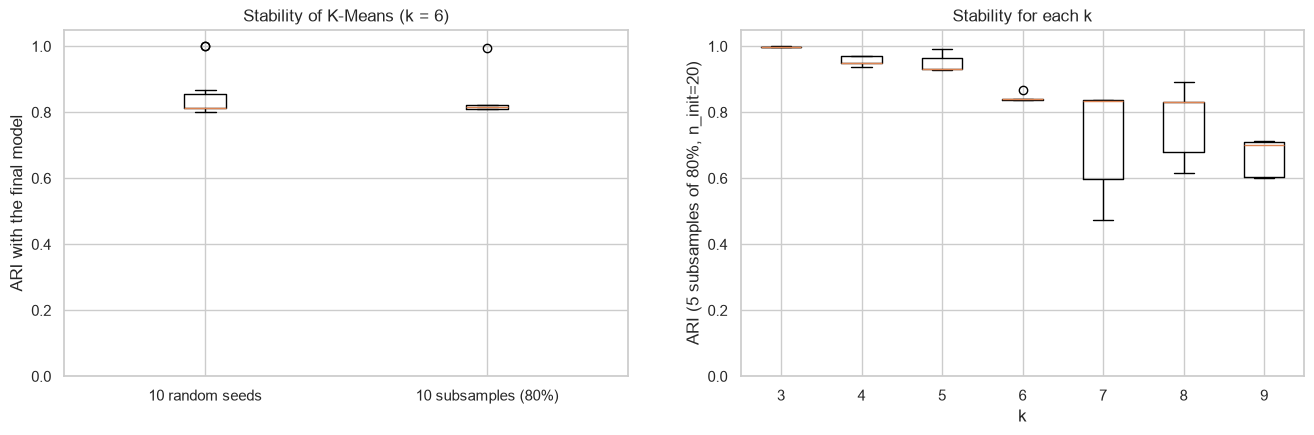

Seeds:      ARI mean 0.855, min 0.800
Subsamples: ARI mean 0.833, min 0.809
{3: 0.999, 4: 0.956, 5: 0.949, 6: 0.845, 7: 0.716, 8: 0.77, 9: 0.665}


In [27]:
seed_ari = [adjusted_rand_score(labels_km, KMeans(n_clusters=K, n_init=50, random_state=s).fit_predict(X_scaled)) for s in range(10)]

def subsample_ari(k, labels_ref, n_runs=10, n_init=50):
    out = []
    for s in range(n_runs):
        idx = np.random.default_rng(s).choice(len(X_scaled), size=int(0.8 * len(X_scaled)), replace=False)
        km_sub = KMeans(n_clusters=k, n_init=n_init, random_state=RANDOM_STATE).fit(X_scaled[idx])
        out.append(adjusted_rand_score(labels_ref, km_sub.predict(X_scaled)))
    return out

sub_ari = subsample_ari(K, labels_km)
k_range = range(3, 10)
ari_by_k = {k: subsample_ari(k, KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scaled), n_runs=5, n_init=20)
            for k in k_range}

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].boxplot([seed_ari, sub_ari], tick_labels=["10 random seeds", "10 subsamples (80%)"])
axes[0].set(ylabel="ARI with the final model", title=f"Stability of K-Means (k = {K})", ylim=(0, 1.05))
axes[1].boxplot([ari_by_k[k] for k in k_range], tick_labels=list(k_range))
axes[1].set(xlabel="k", ylabel="ARI (5 subsamples of 80%, n_init=20)", title="Stability for each k", ylim=(0, 1.05))
fig.savefig(FIG_DIR / "18_stability.png", dpi=150, bbox_inches="tight")
plt.show()
print("Seeds:      ARI mean %.3f, min %.3f" % (np.mean(seed_ari), np.min(seed_ari)))
print("Subsamples: ARI mean %.3f, min %.3f" % (np.mean(sub_ari), np.min(sub_ari)))
print({k: round(float(np.mean(v)), 3) for k, v in ari_by_k.items()})

# ---- What this cell does ----
# Stability checks with the adjusted Rand index (ARI, 1 = same clusters):
# 1) seed_ari: refit K-Means with 10 different random seeds and compare with our model;
# 2) sub_ari: refit on 10 random 80% subsamples, assign ALL buildings with that model and compare;
# 3) ari_by_k: the same subsample test for k = 3-9, to see which k values give stable clusters.

- **Seeds:** mean ARI **0.86** (minimum 0.80) over 10 seeds. With 50 starts, K-Means lands on the same solution or a close one.
- **Subsamples:** mean ARI **0.83** (minimum 0.81): fitting on 80% of the buildings gives nearly the same groups for everyone.
- **Across k:** k = 3, 4 and 5 are even more stable (0.95–1.00), and stability drops above 7 (0.67–0.77). **k = 6 (0.85) is the largest k that stays
  stable**, which supports our choice: k = 7+ starts splitting the data in ways that change from sample to sample.

The differences between runs are mostly at the borders between the plain-brick, concrete and risk groups; the terra-cotta and glass groups barely move.

## 5. Interpretation

### 5.1 Size and profile of each cluster

In [28]:
buildings["cluster"] = labels_km
profile = buildings.groupby("cluster")[FEATURES].mean()
profile.insert(0, "share_of_buildings", buildings["cluster"].value_counts(normalize=True).sort_index())
profile.insert(0, "size", buildings["cluster"].value_counts().sort_index())
profile.round(2).T

# ---- What this cell does ----
# Add the cluster to the building table and compute the profile: size, share of buildings and the average of every
# feature per cluster. .T turns the table so clusters are columns (easier to read).

cluster,0,1,2,3,4,5
size,1031.00,6054.00,3263.00,1693.00,2347.00,1375.00
share_of_buildings,0.07,0.38,0.21,0.11,0.15,0.09
share_unsafe,0.23,0.09,0.21,0.23,0.68,0.11
share_swarmp,0.39,0.47,0.44,0.41,0.14,0.44
followups_per_cycle,0.23,0.10,0.26,0.25,0.69,0.18
log_penalty,3.16,3.25,3.69,3.32,3.98,2.72
n_cycles,2.58,3.31,3.92,3.65,3.23,2.90
n_materials,0.72,1.28,2.83,2.42,1.39,3.51
MATERIAL_MASONRY,0.00,1.00,1.00,1.00,0.99,0.70
MATERIAL_TERRA_COTTA,0.03,0.00,0.94,0.05,0.10,0.08


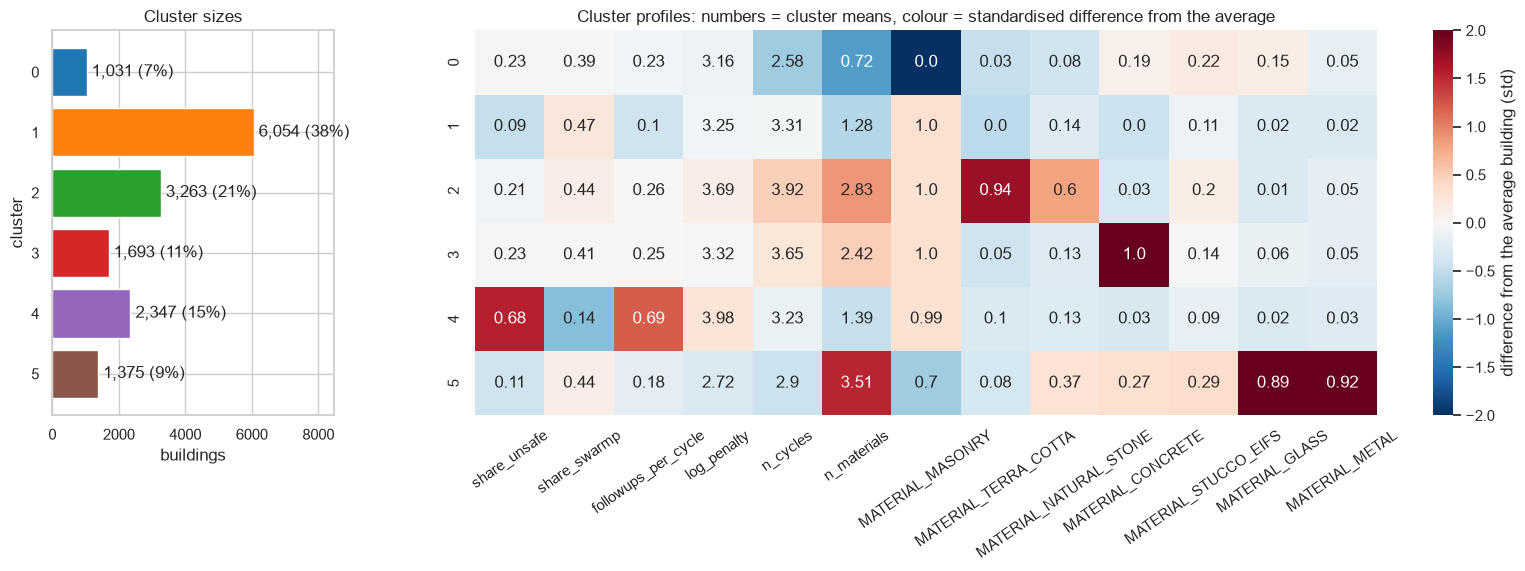

In [29]:
CLUSTER_COLORS = dict(zip(range(K), sns.color_palette("tab10", K)))
means = buildings.groupby("cluster")[FEATURES].mean()
z = (means - X.mean()) / X.std()

fig, axes = plt.subplots(1, 2, figsize=(20, 5), gridspec_kw={"width_ratios": [1, 4]})
sizes = buildings["cluster"].value_counts().sort_index()
axes[0].barh(sizes.index.astype(str), sizes, color=[CLUSTER_COLORS[c] for c in sizes.index])
for c, n in sizes.items():
    axes[0].text(n, c, f" {n:,} ({n / len(buildings):.0%})", va="center")
axes[0].invert_yaxis()
axes[0].set(title="Cluster sizes", xlabel="buildings", ylabel="cluster", xlim=(0, sizes.max() * 1.4))
sns.heatmap(z, annot=means.round(2), fmt="", cmap="RdBu_r", center=0, vmin=-2, vmax=2,
            cbar_kws={"label": "difference from the average building (std)"}, ax=axes[1])
axes[1].set(title="Cluster profiles: numbers = cluster means, colour = standardised difference from the average", xlabel="", ylabel="")
axes[1].tick_params(axis="x", rotation=35)
fig.savefig(FIG_DIR / "19_cluster_profiles.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# Left: size of each cluster. Right: heatmap of the cluster averages.
# z = (cluster mean - overall mean) / standard deviation: red = clearly above the average building, blue = below.
# The numbers written in the cells are the real averages (annot). This is the main chart for naming the clusters.

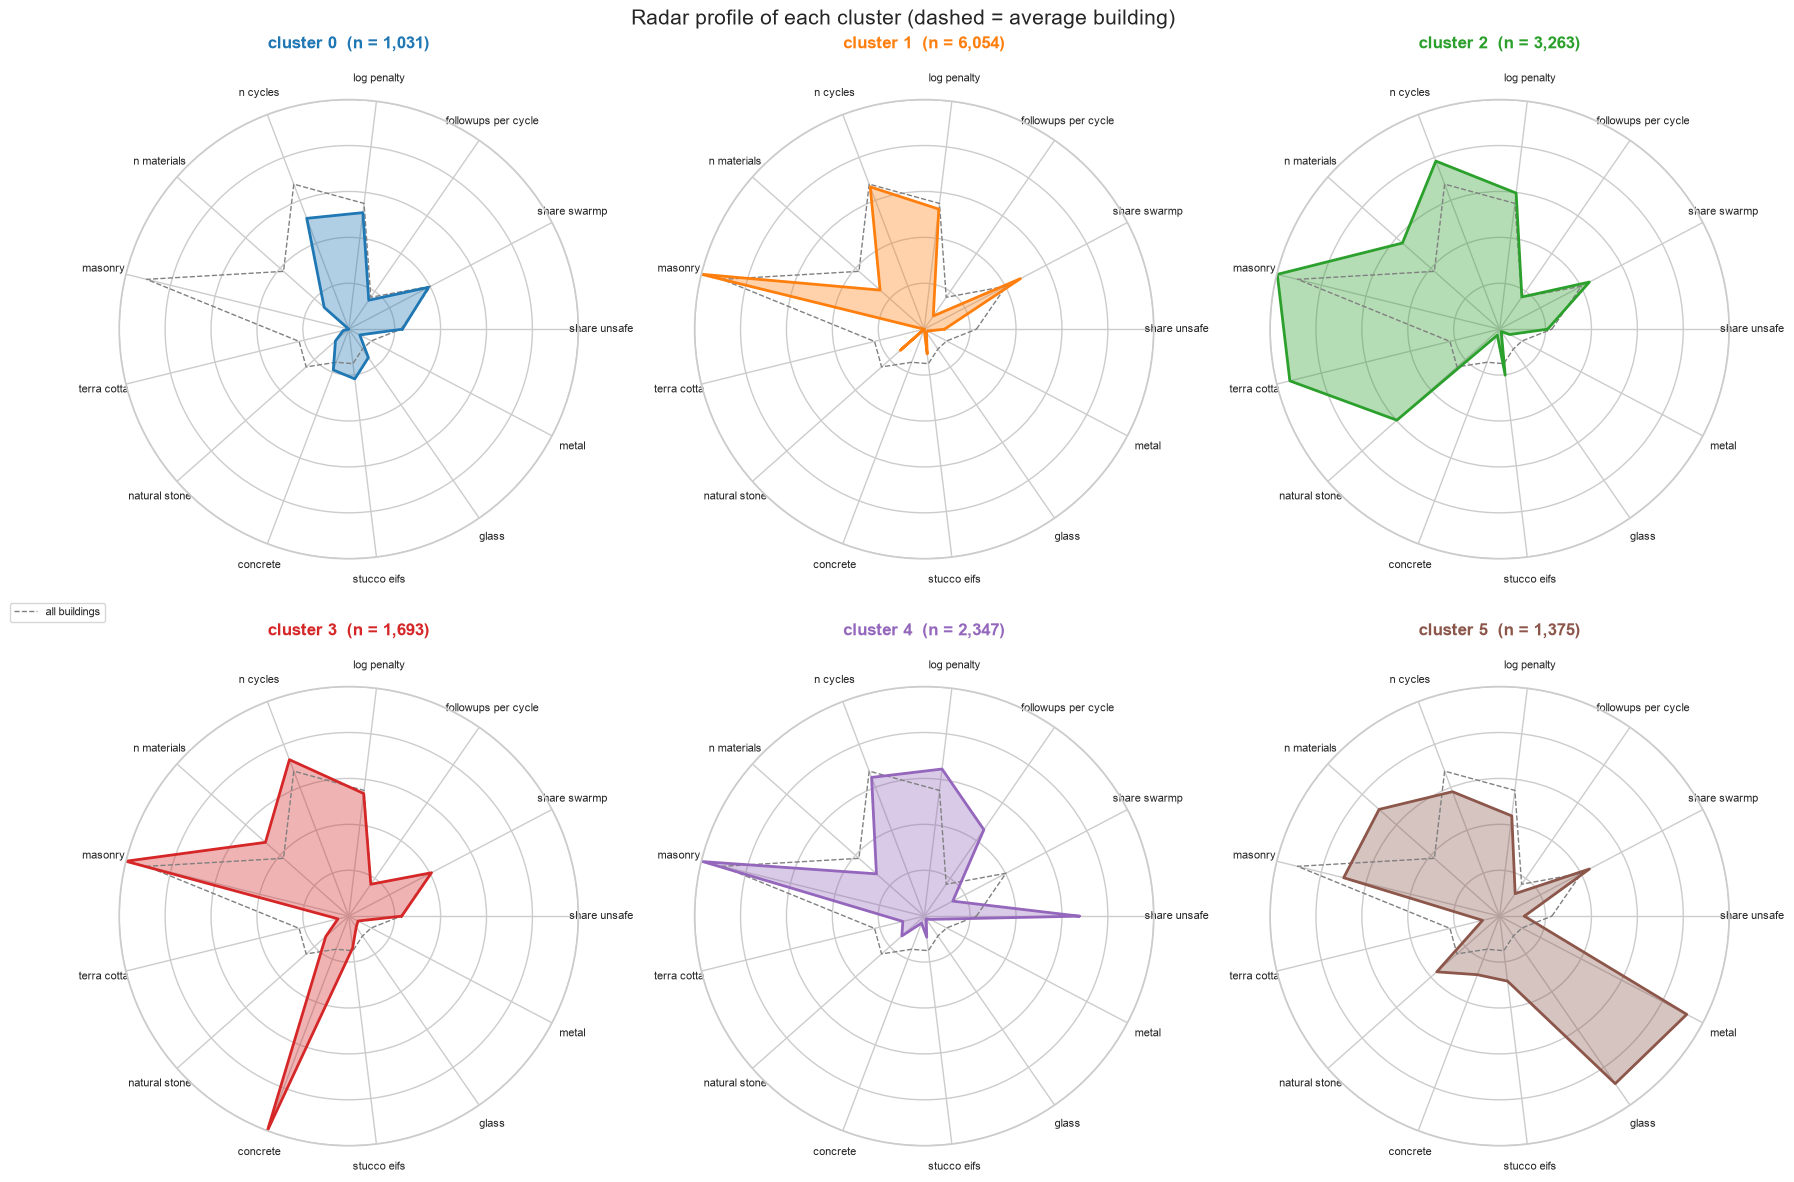

In [30]:
# radar charts: every feature rescaled to 0-1 (shares and flags already are; the others are divided by their 99th percentile)
radar = means.copy()
for col in ["followups_per_cycle", "log_penalty", "n_cycles", "n_materials"]:
    radar[col] = (radar[col] / X[col].quantile(0.99)).clip(upper=1)
labels_r = [f.replace("MATERIAL_", "").replace("_", " ").lower() for f in FEATURES]
angles = np.linspace(0, 2 * np.pi, len(FEATURES), endpoint=False).tolist()
angles += angles[:1]
overall = X.mean().copy()
for col in ["followups_per_cycle", "log_penalty", "n_cycles", "n_materials"]:
    overall[col] = min(overall[col] / X[col].quantile(0.99), 1)

fig, axes = plt.subplots(2, 3, figsize=(18, 12), subplot_kw={"polar": True})
for c, ax in zip(range(K), axes.ravel()):
    vals = radar.loc[c].tolist() + radar.loc[c].tolist()[:1]
    base = overall.tolist() + overall.tolist()[:1]
    ax.plot(angles, base, color="grey", lw=1, ls="--", label="all buildings")
    ax.fill(angles, vals, color=CLUSTER_COLORS[c], alpha=0.35)
    ax.plot(angles, vals, color=CLUSTER_COLORS[c], lw=2)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels_r, fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_yticklabels([])
    ax.set_title(f"cluster {c}  (n = {sizes[c]:,})", fontsize=12, pad=18, color=CLUSTER_COLORS[c], fontweight="bold")
axes[0, 0].legend(loc="lower left", bbox_to_anchor=(-0.25, -0.15), fontsize=8)
fig.suptitle("Radar profile of each cluster (dashed = average building)", fontsize=15)
fig.tight_layout()
fig.savefig(FIG_DIR / "20_cluster_radars.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# Radar charts: one per cluster, with all 13 features on a 0-1 scale (shares and flags are already 0-1; the others are
# divided by their 99th percentile). Dashed grey = the average building, so you see at a glance what makes each cluster different.

### 5.2 Cross-tabulations with variables we did **not** cluster on

In [31]:
aside = buildings.groupby("cluster").agg(
    median_year_built=("year_built", "median"),
    built_before_1930=("year_built", lambda s: (s < 1930).mean()),
    median_floors=("num_floors", "median"),
    median_penalty_usd=("total_penalty", "median"),
    entered_after_cycle_6=("first_cycle", lambda s: (s > 6).mean()),
    ever_unsafe=("ever_unsafe", "mean"),
    latest_unsafe=("latest_status", lambda s: (s == "UNSAFE").mean()),
    manhattan=("BOROUGH", lambda s: (s == "MANHATTAN").mean()),
)
aside.round(2)

# ---- What this cell does ----
# Cross-tabulation with variables NOT used for clustering: median year built, share built before 1930, median floors,
# median penalty, share that entered FISP after cycle 6, share ever / currently UNSAFE, share in Manhattan.
# If these differ between clusters, the clusters mean something beyond the features we used.

,median_year_built,built_before_1930,median_floors,median_penalty_usd,entered_after_cycle_6,ever_unsafe,latest_unsafe,manhattan
cluster,,,,,,,,
0,1964.0,0.11,9.0,19000.0,0.40,0.45,0.20,0.41
1,1955.0,0.23,7.0,22550.0,0.24,0.30,0.11,0.45
2,1920.0,0.82,11.0,36000.0,0.05,0.56,0.25,0.88
3,1964.0,0.13,12.0,24000.0,0.19,0.54,0.27,0.51
4,1951.0,0.28,8.0,119250.0,0.21,1.00,0.69,0.44
5,1997.0,0.17,15.0,7000.0,0.53,0.27,0.13,0.77


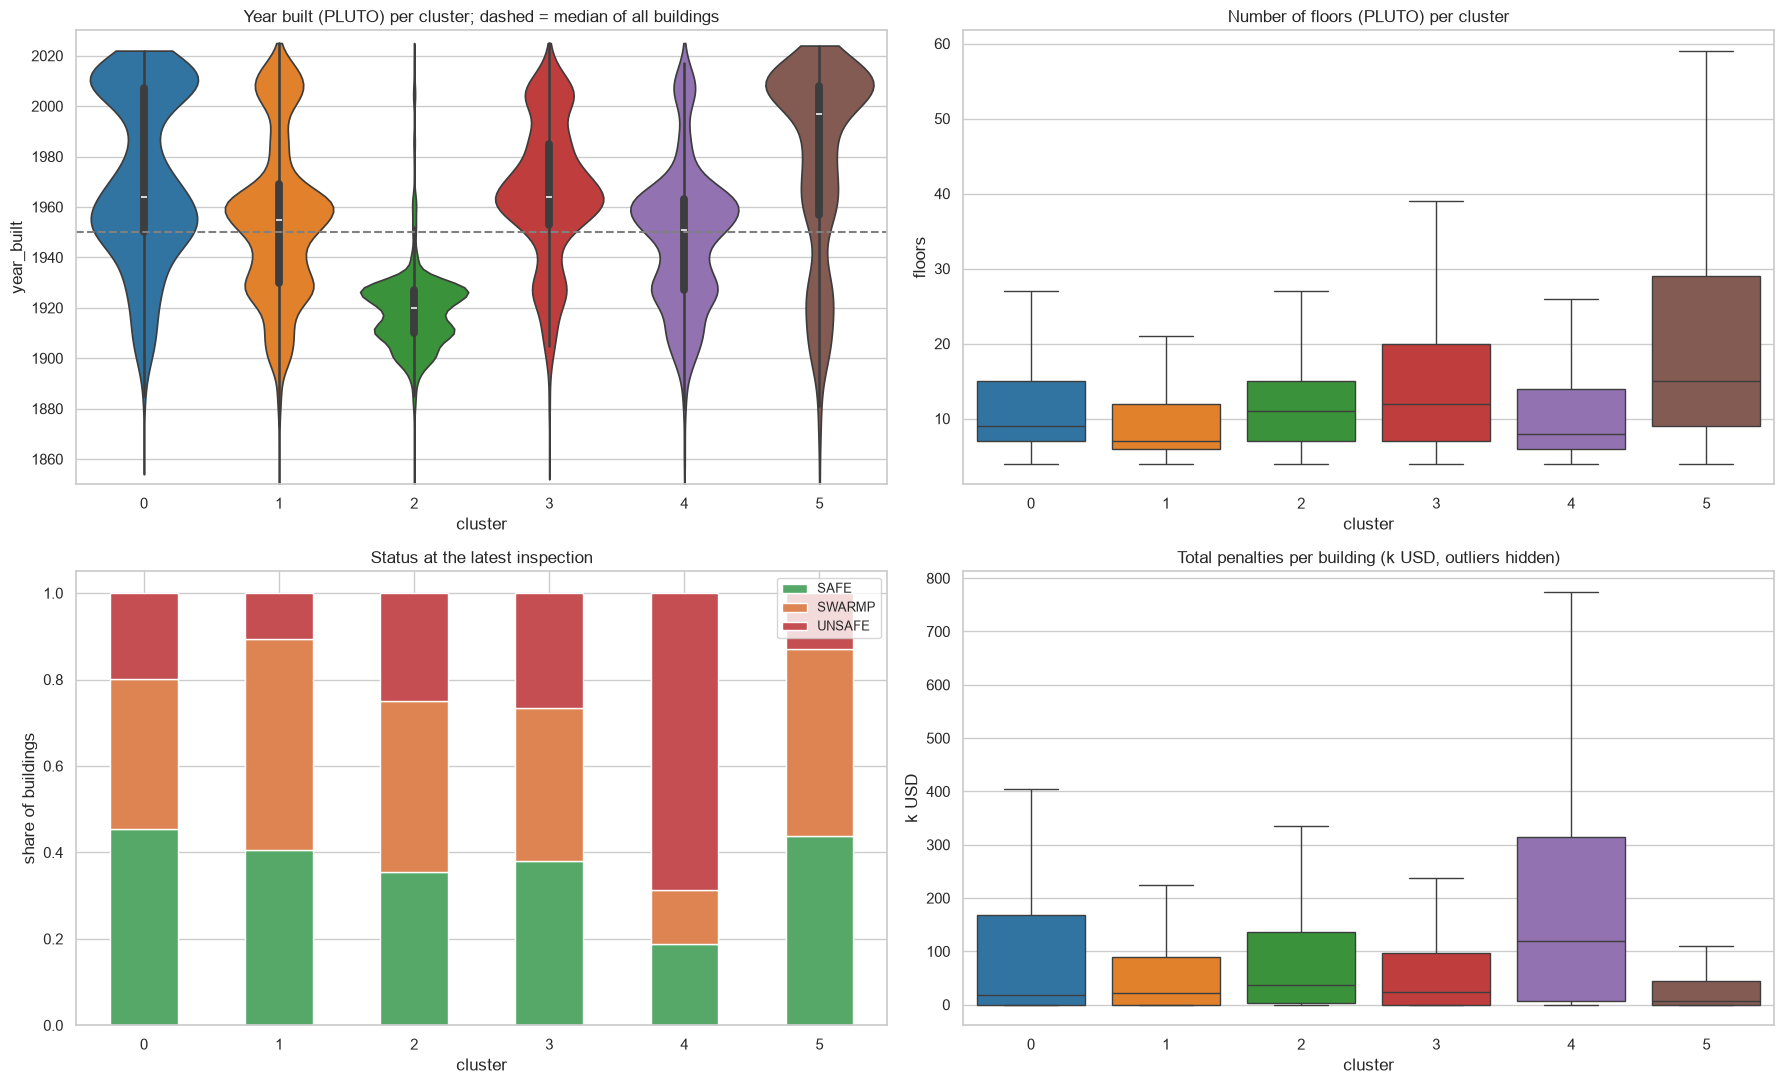

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11))
order = list(range(K))
pal = [CLUSTER_COLORS[c] for c in order]

sns.violinplot(data=buildings, x="cluster", y="year_built", hue="cluster", palette=pal, legend=False, cut=0, ax=axes[0, 0])
axes[0, 0].axhline(buildings["year_built"].median(), ls="--", color="grey")
axes[0, 0].set(title="Year built (PLUTO) per cluster; dashed = median of all buildings", ylim=(1850, 2030))

sns.boxplot(data=buildings, x="cluster", y=buildings["num_floors"].clip(upper=60), hue="cluster", palette=pal, legend=False,
            showfliers=False, ax=axes[0, 1])
axes[0, 1].set(title="Number of floors (PLUTO) per cluster", ylabel="floors")

status = pd.crosstab(buildings["cluster"], buildings["latest_status"], normalize="index")[list(STATUS_COLORS)]
status.plot.bar(stacked=True, color=STATUS_COLORS, ax=axes[1, 0], rot=0)
axes[1, 0].set(title="Status at the latest inspection", ylabel="share of buildings")
axes[1, 0].legend(loc="upper right", fontsize=9)

sns.boxplot(data=buildings, x="cluster", y=buildings["total_penalty"] / 1000, hue="cluster", palette=pal, legend=False,
            showfliers=False, ax=axes[1, 1])
axes[1, 1].set(title="Total penalties per building (k USD, outliers hidden)", ylabel="k USD")

fig.tight_layout()
fig.savefig(FIG_DIR / "21_clusters_vs_aside_variables.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# Four charts per cluster, again with variables kept aside: year built (violin = distribution shape), number of floors
# (boxplot), status at the latest inspection (stacked bars) and total penalties (boxplot without extreme outliers).

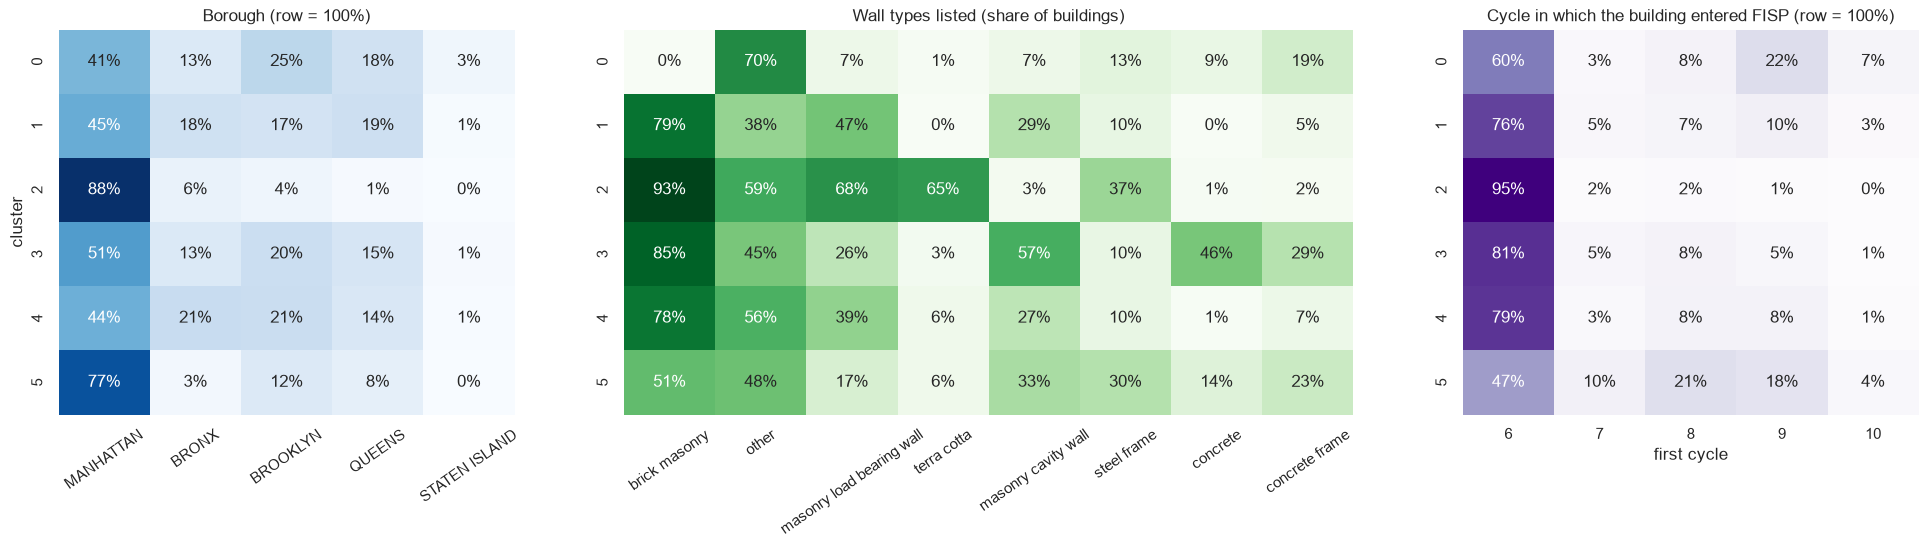

All buildings by borough: {'MANHATTAN': 0.57, 'BROOKLYN': 0.15, 'BRONX': 0.14, 'QUEENS': 0.13, 'STATEN ISLAND': 0.01}


In [33]:
borough_tab = pd.crosstab(buildings["cluster"], buildings["BOROUGH"], normalize="index")[BOROUGH_ORDER]
wall_tab = buildings.groupby("cluster")[WALL_TYPES].mean()
wall_tab.columns = [c.replace("WALL_TYPE_", "").replace("_", " ").lower() for c in wall_tab.columns]
cycle_tab = pd.crosstab(buildings["cluster"], buildings["first_cycle"], normalize="index")

fig, axes = plt.subplots(1, 3, figsize=(24, 5), gridspec_kw={"width_ratios": [5, 8, 5]})
sns.heatmap(borough_tab, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="Borough (row = 100%)", xlabel="", ylabel="cluster")
sns.heatmap(wall_tab, annot=True, fmt=".0%", cmap="Greens", cbar=False, ax=axes[1])
axes[1].set(title="Wall types listed (share of buildings)", xlabel="", ylabel="")
sns.heatmap(cycle_tab, annot=True, fmt=".0%", cmap="Purples", cbar=False, ax=axes[2])
axes[2].set(title="Cycle in which the building entered FISP (row = 100%)", xlabel="first cycle", ylabel="")
for ax in axes[:2]:
    ax.tick_params(axis="x", rotation=35)
fig.savefig(FIG_DIR / "22_crosstabs_borough_wall_cycle.png", dpi=150, bbox_inches="tight")
plt.show()
print("All buildings by borough:", buildings["BOROUGH"].value_counts(normalize=True).round(2).to_dict())

# ---- What this cell does ----
# Three heatmaps per cluster: borough (% of the cluster in each borough), wall types (% listing each wall type)
# and the cycle in which the building first entered FISP. Compare with the overall borough split printed below (57% Manhattan).

### 5.3 Naming the clusters

Each name comes from the **profile** (what was clustered on) and is checked with the **variables kept aside** (year built, floors, borough, wall types,
latest status, entry cycle):

| # | Name | Size | Why this name |
|---|---|---|---|
| 0 | **non-masonry or unreported facades** | 1,031 (7%) | 0% masonry, and **49% list no material at all**; the rest list "other", stucco, glass or concrete. 70% list wall type "other". Median year 1964, 40% entered FISP after cycle 6. A mix of non-brick facades and **incomplete filings**: we name it for what we know, and say what we don't |
| 1 | **plain brick, low risk** | 6,054 (38%) | Only masonry (1.3 materials on average), the **lowest share UNSAFE (0.09)** and the fewest follow-ups. Built ~1955, **7 floors**, spread over all boroughs (45% Manhattan, below the 57% average). The ordinary post-war brick apartment building |
| 2 | **pre-war terra cotta & stone** | 3,263 (21%) | **94% terra cotta, 60% natural stone**, 2.8 materials. Kept aside: **median year 1920, 82% built before 1930, 88% in Manhattan**, 65% list a terra-cotta wall type, 95% in FISP since cycle 6. The ornamented pre-war stock, recovered without seeing the year |
| 3 | **post-war concrete & brick** | 1,693 (11%) | **100% concrete + masonry**. Kept aside: median **1964, 12 floors**, 46% list a concrete wall and 57% a cavity wall. Average risk (0.23) |
| 4 | **repeatedly unsafe brick facades** | 2,347 (15%) | Masonry facades with **share UNSAFE 0.68** (3 times the average), **0.69 follow-ups per cycle**, **every building UNSAFE at least once**, 69% UNSAFE at the latest inspection, median penalties **119,000 USD** (5 times the others). Built ~1951, all boroughs. Defined by behaviour, not by material |
| 5 | **modern glass & metal curtain walls** | 1,375 (9%) | **89% glass, 92% metal**, 3.5 materials. Kept aside: **median year 1997, 15 floors**, 77% Manhattan, **53% entered FISP after cycle 6** (new towers), lowest penalties (median 7,000 USD) |

Names 1–5 are confirmed by variables the model never saw (year, floors, borough, wall type). Name 0 is the weakest: it groups
buildings by what they do **not** report, so it is partly a **data-quality** group (worth a DOB follow-up on incomplete filings in itself).

In [34]:
CLUSTER_NAMES = {
    0: "non-masonry or unreported facades",
    1: "plain brick, low risk",
    2: "pre-war terra cotta & stone",
    3: "post-war concrete & brick",
    4: "repeatedly unsafe brick facades",
    5: "modern glass & metal curtain walls",
}
buildings["cluster_name"] = buildings["cluster"].map(CLUSTER_NAMES)
NAME_COLORS = {CLUSTER_NAMES[c]: CLUSTER_COLORS[c] for c in range(K)}

summary = buildings.groupby(["cluster", "cluster_name"]).agg(
    buildings=("BIN", "size"),
    share_unsafe=("share_unsafe", "mean"),
    median_year_built=("year_built", "median"),
    manhattan=("BOROUGH", lambda s: (s == "MANHATTAN").mean()),
).reset_index()
summary.insert(3, "share_of_buildings", summary["buildings"] / len(buildings))
summary.round(2)

# ---- What this cell does ----
# The names of the clusters, chosen by our team from the profiles, radars, cross-tabs and maps above.
# They are mapped onto every building (cluster_name). NAME_COLORS keeps one colour per name.
# The summary table is the final overview: size, share, risk, year built and share in Manhattan per named cluster.

,cluster,cluster_name,buildings,share_of_buildings,share_unsafe,median_year_built,manhattan
0,0,non-masonry or unreported facades,1031,0.07,0.23,1964.0,0.41
1,1,"plain brick, low risk",6054,0.38,0.09,1955.0,0.45
2,2,pre-war terra cotta & stone,3263,0.21,0.21,1920.0,0.88
3,3,post-war concrete & brick,1693,0.11,0.23,1964.0,0.51
4,4,repeatedly unsafe brick facades,2347,0.15,0.68,1951.0,0.44
5,5,modern glass & metal curtain walls,1375,0.09,0.11,1997.0,0.77


### 5.4 The clusters on the PCA and t-SNE maps

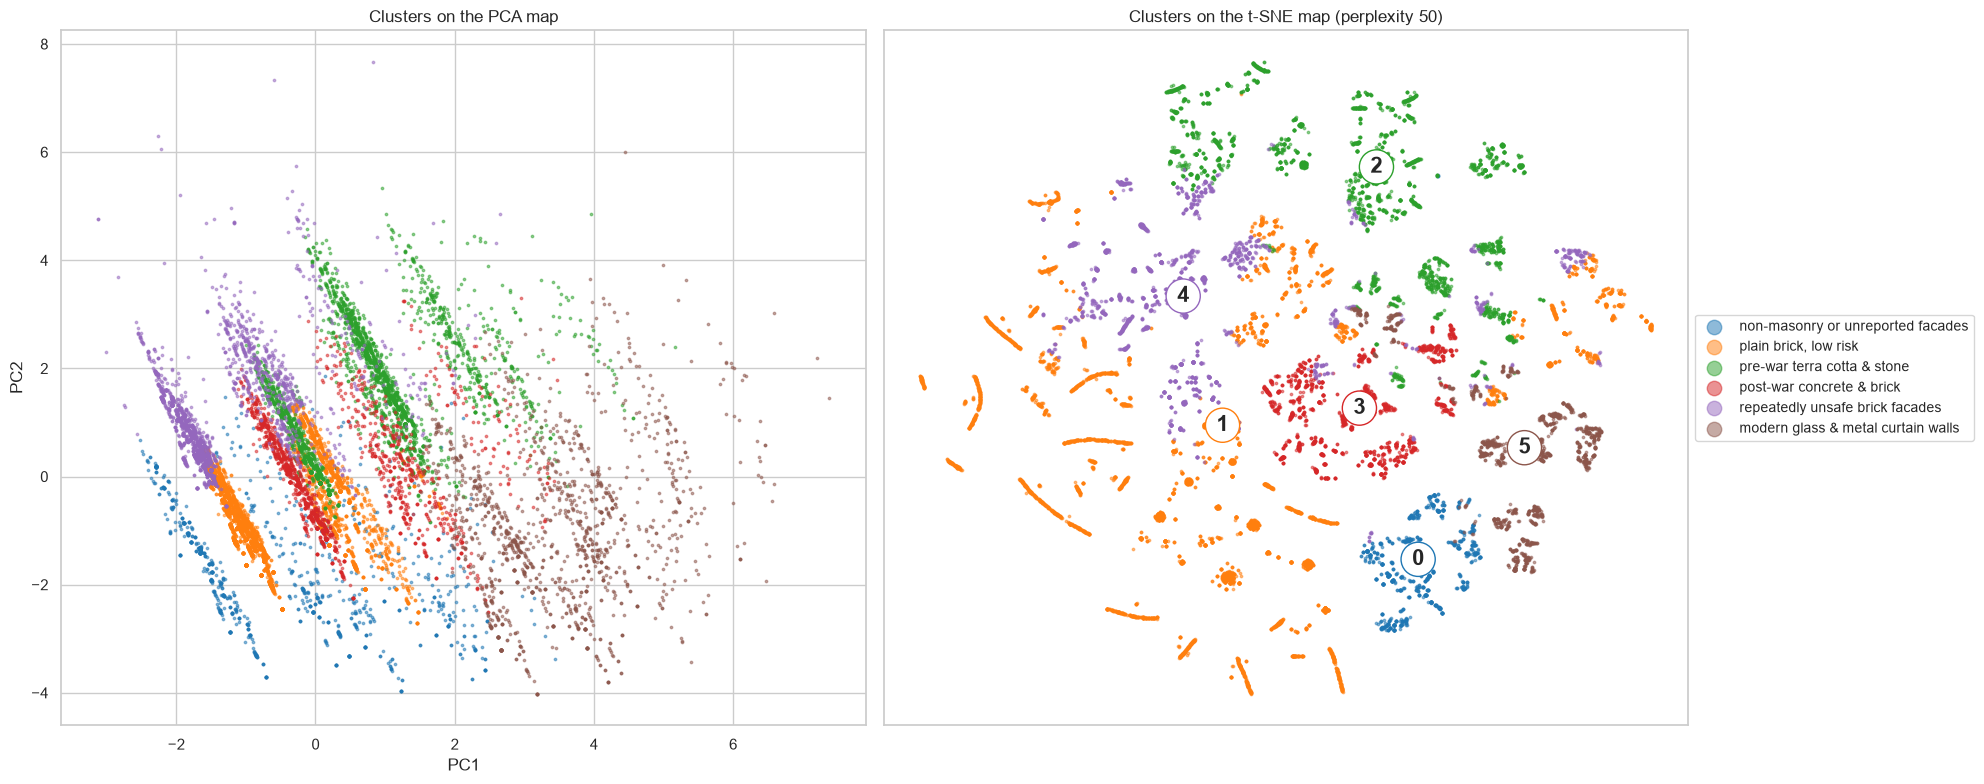

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for c in range(K):
    m = labels_km == c
    axes[0].scatter(pca_xy[m, 0], pca_xy[m, 1], s=3, alpha=0.5, color=CLUSTER_COLORS[c], label=CLUSTER_NAMES[c])
    axes[1].scatter(tsne_xy[m, 0], tsne_xy[m, 1], s=3, alpha=0.5, color=CLUSTER_COLORS[c], label=CLUSTER_NAMES[c])
    cx, cy = np.median(tsne_xy[m], axis=0)
    axes[1].text(cx, cy, str(c), fontsize=16, fontweight="bold", ha="center", va="center",
                 bbox=dict(boxstyle="circle", fc="white", ec=CLUSTER_COLORS[c]))
axes[0].set(title="Clusters on the PCA map", xlabel="PC1", ylabel="PC2")
axes[1].set(title="Clusters on the t-SNE map (perplexity 50)", xticks=[], yticks=[])
axes[1].legend(markerscale=6, fontsize=10, loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
fig.savefig(FIG_DIR / "23_clusters_pca_tsne.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# The named clusters drawn on the PCA map (left) and the t-SNE map (right). The number in a circle marks the middle
# (median position) of each cluster on the t-SNE map. Remember: on t-SNE, sizes and distances between groups mean nothing.

On the **PCA** map the groups overlap a lot, as the silhouette predicted: PCA only keeps 35% of the variance in 2D. On the **t-SNE** map the
material groups occupy clear regions (terra cotta at the top, glass on the right), while the **repeatedly unsafe** group is spread over the
**edges of the brick islands**: it is the same kind of building as the plain brick group, but with a bad inspection record.

### 5.5 The clusters on the map of New York

We never gave the model any location, so any geography in these maps comes from the buildings themselves.

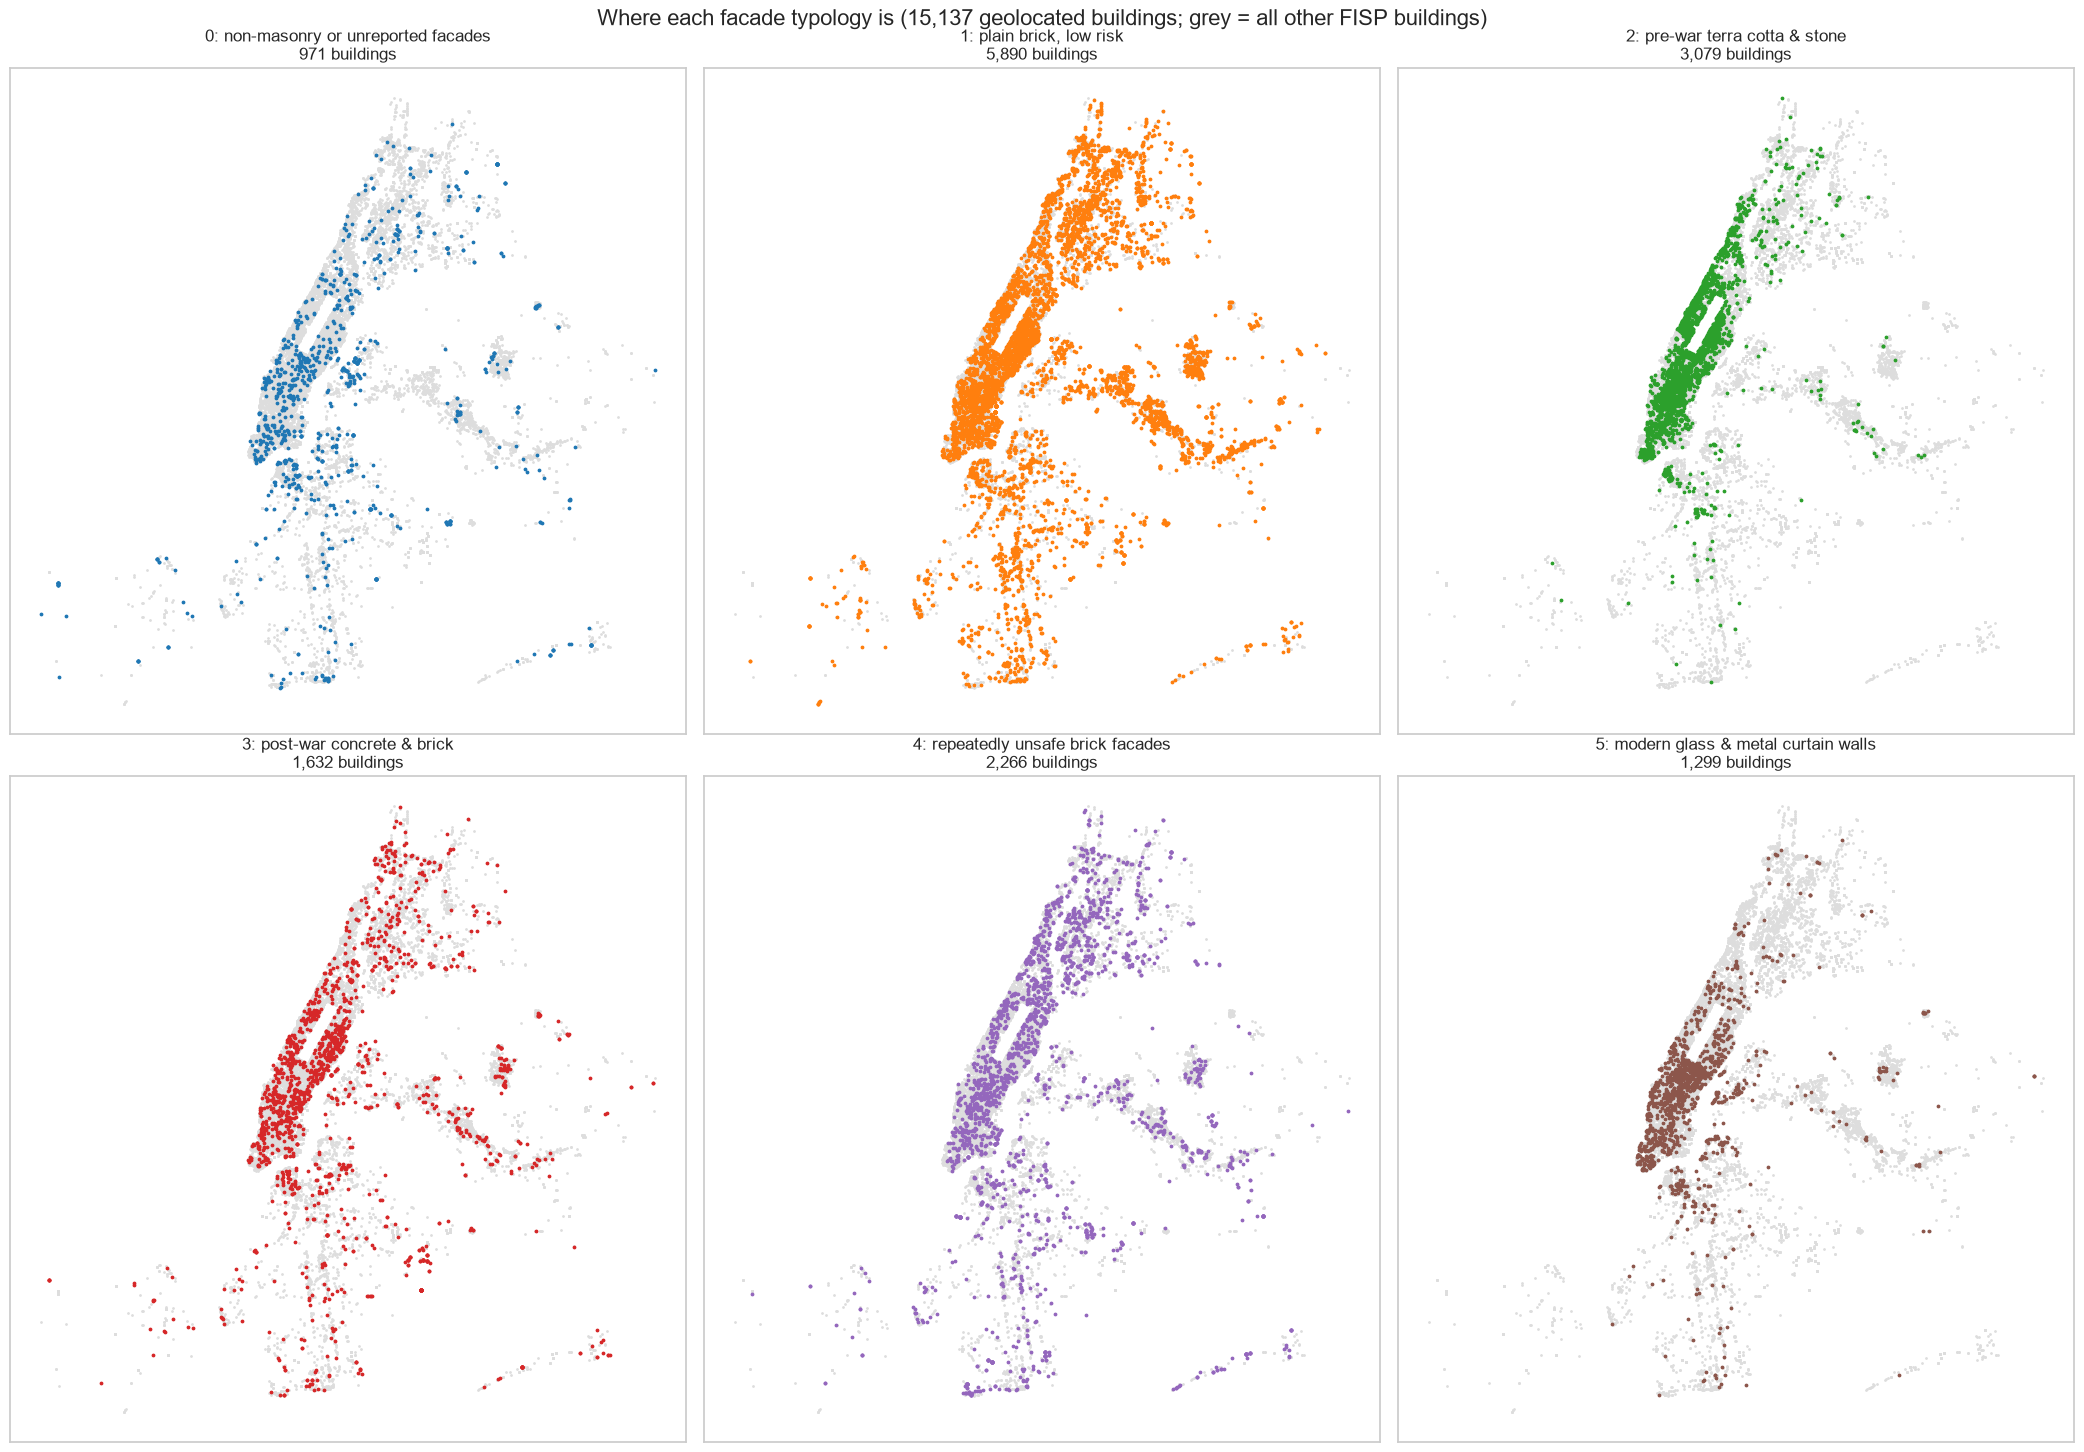

In [36]:
geo_ok = buildings["latitude"].notna().to_numpy()
ASPECT = 1 / np.cos(np.radians(40.7))

def nyc_axes(ax, title, bounds=None):
    ax.set_aspect(ASPECT)
    ax.set(title=title, xticks=[], yticks=[])
    if bounds:
        ax.set(xlim=bounds[0], ylim=bounds[1])

fig, axes = plt.subplots(2, 3, figsize=(21, 15))
for c, ax in zip(range(K), axes.ravel()):
    ax.scatter(buildings.loc[geo_ok, "longitude"], buildings.loc[geo_ok, "latitude"], s=1, color="#dddddd")
    m = geo_ok & (labels_km == c)
    ax.scatter(buildings.loc[m, "longitude"], buildings.loc[m, "latitude"], s=3, color=CLUSTER_COLORS[c])
    nyc_axes(ax, f"{c}: {CLUSTER_NAMES[c]}\n{m.sum():,} buildings")
fig.suptitle(f"Where each facade typology is ({geo_ok.sum():,} geolocated buildings; grey = all other FISP buildings)", fontsize=16)
fig.tight_layout()
fig.savefig(FIG_DIR / "24_map_typologies.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# Maps of New York, one small map per cluster: grey = all FISP buildings, colour = buildings of that cluster.
# geo_ok = buildings that have coordinates (matched to PLUTO). nyc_axes() is a helper that fixes the map proportions and
# removes the axis ticks. The model never saw the location, so any pattern here comes from the buildings themselves.

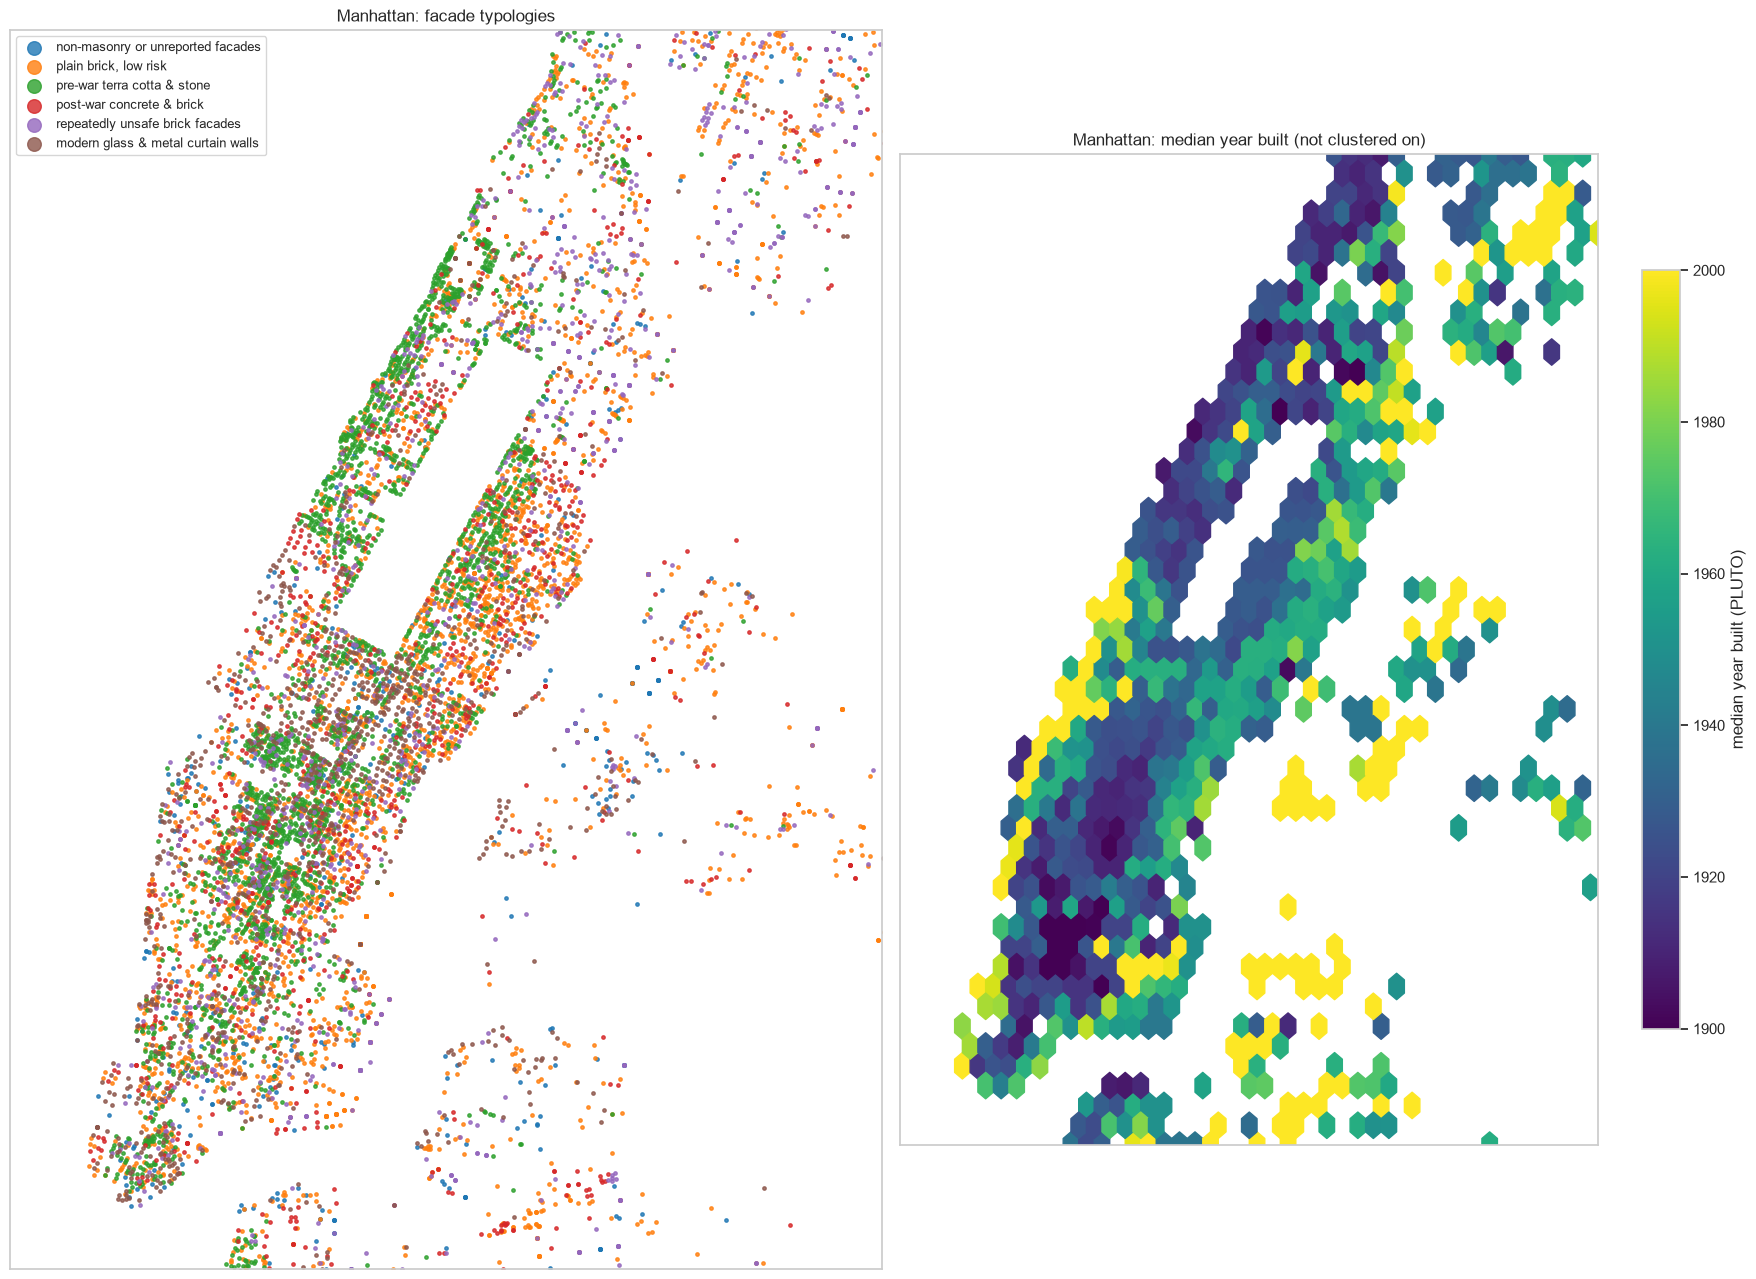

In [37]:
MANHATTAN_BOUNDS = ((-74.03, -73.90), (40.695, 40.835))
fig, axes = plt.subplots(1, 2, figsize=(18, 13))
for c in range(K):
    m = geo_ok & (labels_km == c)
    axes[0].scatter(buildings.loc[m, "longitude"], buildings.loc[m, "latitude"], s=6, alpha=0.8, color=CLUSTER_COLORS[c],
                    label=CLUSTER_NAMES[c])
nyc_axes(axes[0], "Manhattan: facade typologies", MANHATTAN_BOUNDS)
axes[0].legend(markerscale=4, loc="upper left", fontsize=9)

g = buildings[geo_ok]
hb = axes[1].hexbin(g["longitude"], g["latitude"], C=g["year_built"], reduce_C_function=np.nanmedian, gridsize=45,
                    extent=(*MANHATTAN_BOUNDS[0], *MANHATTAN_BOUNDS[1]), cmap="viridis", mincnt=3, vmin=1900, vmax=2000)
plt.colorbar(hb, ax=axes[1], shrink=0.6, label="median year built (PLUTO)")
nyc_axes(axes[1], "Manhattan: median year built (not clustered on)", MANHATTAN_BOUNDS)
fig.tight_layout()
fig.savefig(FIG_DIR / "25_map_manhattan_zoom.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# Zoom on Manhattan. Left: every building coloured by its cluster. Right: hexbin map of the median year built per
# hexagon (PLUTO, not used in the clustering), to compare the typologies with the age of the neighbourhoods.

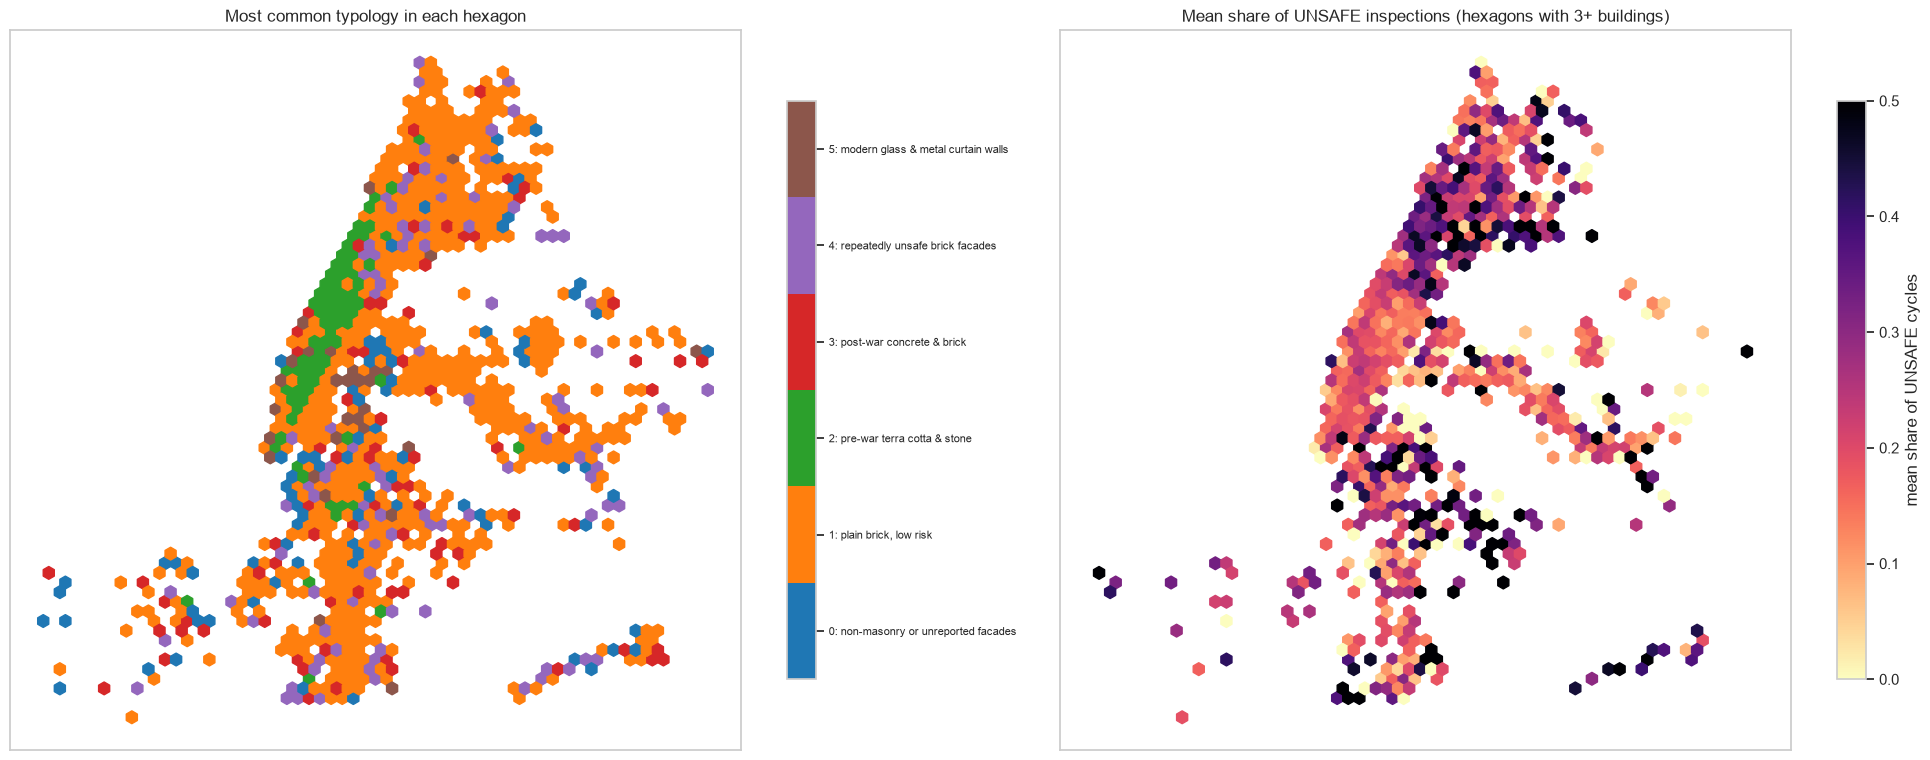

In [38]:
# for each hexagon: the most common typology, and the share of UNSAFE cycles
g = buildings[geo_ok].copy()
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
cmap = plt.matplotlib.colors.ListedColormap([CLUSTER_COLORS[c] for c in range(K)])
hb0 = axes[0].hexbin(g["longitude"], g["latitude"], C=g["cluster"], reduce_C_function=lambda v: np.bincount(np.asarray(v, dtype=int)).argmax(),
                     gridsize=60, mincnt=1, cmap=cmap, vmin=-0.5, vmax=K - 0.5)
cb = plt.colorbar(hb0, ax=axes[0], shrink=0.6, ticks=range(K))
cb.ax.set_yticklabels([f"{c}: {CLUSTER_NAMES[c]}" for c in range(K)], fontsize=8)
nyc_axes(axes[0], "Most common typology in each hexagon")
hb1 = axes[1].hexbin(g["longitude"], g["latitude"], C=g["share_unsafe"], reduce_C_function=np.mean, gridsize=60, mincnt=3,
                     cmap="magma_r", vmin=0, vmax=0.5)
plt.colorbar(hb1, ax=axes[1], shrink=0.6, label="mean share of UNSAFE cycles")
nyc_axes(axes[1], "Mean share of UNSAFE inspections (hexagons with 3+ buildings)")
fig.tight_layout()
fig.savefig(FIG_DIR / "26_map_hexbin_dominant_and_risk.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- What this cell does ----
# Two city-wide hexbin maps. Left: in each hexagon, the most common cluster (bincount(...).argmax() = the most frequent label).
# Right: the average share of UNSAFE inspections per hexagon (only hexagons with 3+ buildings), to see where risk concentrates.

**What the maps show** (the model never saw any location):

- **Pre-war terra cotta & stone** draws **Manhattan almost alone**: the Upper West and Upper East Sides along Central Park (the park is the empty
  rectangle), Midtown and Lower Manhattan, plus a few pockets in the Bronx and in north-west Brooklyn.
- **Modern glass & metal** concentrates in **Midtown and Lower Manhattan**, Long Island City and Downtown Brooklyn: the post-1990 towers.
- **Plain brick, low risk** is the **background of the outer boroughs**: Queens corridors (Queens Boulevard), Brooklyn, the Bronx; it is the most
  common typology in most hexagons outside Manhattan.
- **Repeatedly unsafe brick** is spread over the whole city, with a **visible concentration in the Bronx and Upper Manhattan (Harlem,
  Washington Heights)**, and along the Rockaways. The hexbin of the share of UNSAFE inspections (right) confirms it: the darkest areas are the Bronx,
  Harlem and parts of central Brooklyn, while Midtown is pale.
- **Concrete & brick** and **non-masonry** groups have no strong geography: they are scattered across all boroughs.

The maps give the use case its practical form: **a terra-cotta programme is a Manhattan programme**, **a curtain-wall programme is a Midtown /
Downtown / LIC programme**, and **an enforcement programme for repeatedly unsafe facades should look first at the Bronx and Upper Manhattan**.

## 6. Save and reuse the model

The final model is **K-Means**, which has `.predict()`, so the saved pipeline (scaler + K-Means) assigns any new building directly; no
"assigner" is needed. We refit the same pipeline on the raw 13 columns, so a user only passes a `DataFrame` with those columns, and check
that it reproduces our clusters exactly.

In [39]:
model = make_pipeline(StandardScaler(), KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE))
model.fit(X)
assert adjusted_rand_score(labels_km, model.predict(X)) == 1.0
joblib.dump(model, MODEL_DIR / "model.joblib")
print("Saved", MODEL_DIR / "model.joblib", f"({(MODEL_DIR / 'model.joblib').stat().st_size / 1024:.0f} KB)")

# ---- What this cell does ----
# Save the final model. make_pipeline puts the StandardScaler and K-Means together, so the saved file takes the raw 13
# columns and does the scaling itself. We fit it on X (unscaled) and check with ARI = 1.0 that it gives exactly the same
# clusters as above. joblib.dump writes models/model.joblib (uploaded to Hugging Face, not to GitHub).

Saved ..\models\model.joblib (64 KB)


**Reload and assign a hand-made example:** a pre-war Manhattan apartment building with a brick facade and terra-cotta and stone ornament,
4 cycles in FISP (SWARMP twice, SAFE twice), one amended filing, 15,000 USD of penalties.

In [40]:
reloaded = joblib.load(MODEL_DIR / "model.joblib")
example = pd.DataFrame([{
    "share_unsafe": 0.0, "share_swarmp": 0.5, "followups_per_cycle": 0.25, "log_penalty": np.log10(15000 + 1),
    "n_cycles": 4, "n_materials": 3,
    "MATERIAL_MASONRY": 1, "MATERIAL_TERRA_COTTA": 1, "MATERIAL_NATURAL_STONE": 1, "MATERIAL_CONCRETE": 0,
    "MATERIAL_STUCCO_EIFS": 0, "MATERIAL_GLASS": 0, "MATERIAL_METAL": 0,
}])
c = int(reloaded.predict(example[FEATURES])[0])
print("Cluster", c, "->", CLUSTER_NAMES[c])

# ---- What this cell does ----
# Reuse test: reload the saved file and assign a hand-made building (pre-war brick with terra cotta and stone, never UNSAFE).
# example[FEATURES] puts the columns in the right order; predict() returns the cluster number, which we translate into its name.

Cluster 2 -> pre-war terra cotta & stone


## 7. Export the clustered dataset (the main deliverable)

One row per building with:

- **identifiers and location:** `BIN`, `BBL`, `BOROUGH`, `BLOCK`, `LOT`, `latitude`, `longitude` (lot centroid from PLUTO). **No street addresses or owner names.**
- **context from PLUTO:** `year_built`, `num_floors`.
- **engineered features:** cycles, statuses, shares, follow-ups, penalties, number of materials / wall types, and the 0/1 material and wall-type flags.
- **clusters:** `cluster`, `cluster_name` (K-Means, our final model) and `cluster_ward` (Ward, for comparison).
- **map coordinates:** `pca_x`, `pca_y`, `tsne_x`, `tsne_y`.

In [41]:
final = buildings.copy()
final["cluster_ward"] = labels_ward
final[["pca_x", "pca_y"]] = pca_xy
final[["tsne_x", "tsne_y"]] = tsne_xy

ordered = (["BIN", "BBL", "BOROUGH", "BLOCK", "LOT", "latitude", "longitude", "year_built", "num_floors",
            "n_cycles", "first_cycle", "last_cycle", "first_filing_year", "last_filing_year",
            "n_safe", "n_swarmp", "n_unsafe", "share_swarmp", "share_unsafe", "ever_unsafe", "latest_status",
            "n_followups", "followups_per_cycle",
            "total_penalty", "failure_to_correct_penalty", "late_filing_penalty", "log_penalty",
            "n_materials", "n_wall_types"] + MATERIALS + WALL_TYPES +
           ["cluster", "cluster_name", "cluster_ward", "pca_x", "pca_y", "tsne_x", "tsne_y"])
final = final[ordered]
for col in ["share_swarmp", "share_unsafe", "followups_per_cycle", "log_penalty", "pca_x", "pca_y", "tsne_x", "tsne_y"]:
    final[col] = final[col].round(4)
final["year_built"] = final["year_built"].astype("Int64")

assert final["BIN"].is_unique
print("Missing values per column (only PLUTO columns may have some):")
print(final.isna().sum()[final.isna().sum() > 0])
final.to_csv(DATASET_DIR / "nyc_facade_typologies.csv", index=False)
print(final.shape, f"-> {(DATASET_DIR / 'nyc_facade_typologies.csv').stat().st_size / 1e6:.1f} MB")
final.head()

# ---- What this cell does ----
# Build the published dataset: the building table + cluster_ward + the PCA and t-SNE coordinates, with the columns in a
# readable order (identifiers, PLUTO context, history, penalties, materials, clusters, coordinates). Decimals are rounded,
# year_built becomes a nullable integer, and we check that every BIN is unique. Only the PLUTO columns may be empty (626 buildings).
# to_csv writes dataset/nyc_facade_typologies.csv (uploaded to Hugging Face).

Missing values per column (only PLUTO columns may have some):
latitude      626
longitude     626
year_built    628
num_floors    625
dtype: int64


(15763, 52) -> 3.8 MB


,BIN,BBL,BOROUGH,BLOCK,LOT,latitude,longitude,year_built,num_floors,n_cycles,first_cycle,last_cycle,first_filing_year,last_filing_year,n_safe,n_swarmp,n_unsafe,share_swarmp,share_unsafe,ever_unsafe,latest_status,n_followups,followups_per_cycle,total_penalty,failure_to_correct_penalty,late_filing_penalty,log_penalty,n_materials,n_wall_types,MATERIAL_MASONRY,MATERIAL_OTHER,MATERIAL_TERRA_COTTA,MATERIAL_NATURAL_STONE,MATERIAL_CONCRETE,MATERIAL_STUCCO_EIFS,MATERIAL_GLASS,MATERIAL_METAL,WALL_TYPE_BRICK_MASONRY,WALL_TYPE_OTHER,WALL_TYPE_MASONRY_LOAD_BEARING_WALL,WALL_TYPE_TERRA_COTTA,WALL_TYPE_MASONRY_CAVITY_WALL,WALL_TYPE_STEEL_FRAME,WALL_TYPE_CONCRETE,WALL_TYPE_CONCRETE_FRAME,cluster,cluster_name,cluster_ward,pca_x,pca_y,tsne_x,tsne_y
0,1000005,1000047501,MANHATTAN,4,7501,40.702153,-74.012021,1969,50.0,4,6,9,2006,2022,0,4,0,1.00,0.0,0,SWARMP,0,0.00,0.0,0.0,0.0,0.0000,2,2,0,1,1,0,0,0,1,0,0,1,0,1,0,1,0,0,0,non-masonry or unreported facades,1,2.0332,-2.0301,51.849998,-56.215401
1,1000006,1000057501,MANHATTAN,5,7501,40.702266,-74.010607,1970,40.0,4,6,9,2006,2022,2,0,2,0.00,0.5,1,UNSAFE,4,1.00,160400.0,126400.0,34000.0,5.2052,2,1,1,1,0,0,0,0,1,0,0,1,0,0,1,0,0,0,4,repeatedly unsafe brick facades,1,-0.0222,1.1226,54.536400,-4.829600
2,1000007,1000050010,MANHATTAN,5,10,40.702776,-74.010722,1969,32.0,5,6,10,2009,2026,2,2,1,0.40,0.2,1,SAFE,3,0.60,410000.0,382400.0,27600.0,5.6128,6,3,1,0,0,1,1,1,1,1,1,1,0,0,1,1,0,0,5,modern glass & metal curtain walls,1,5.8585,1.8088,62.244598,-25.879200
3,1000016,1000080044,MANHATTAN,8,44,NaN,NaN,<NA>,NaN,4,6,9,2007,2022,2,0,2,0.00,0.5,1,SAFE,1,0.25,188750.0,165000.0,18750.0,5.2759,1,2,1,1,0,0,0,0,0,0,1,1,1,0,0,0,0,0,4,repeatedly unsafe brick facades,0,-1.7352,0.5490,-50.089199,22.882401
4,1000018,1000090001,MANHATTAN,9,1,40.702759,-74.013301,1970,34.0,4,6,9,2007,2023,1,3,0,0.75,0.0,0,SWARMP,0,0.00,83400.0,0.0,63400.0,4.9212,3,1,1,1,0,0,0,0,1,1,0,1,0,0,0,1,0,0,5,modern glass & metal curtain walls,1,2.9964,-1.4116,87.235497,-19.150299


In [42]:
# figures shown in the dataset card and the model card
for name in ["23_clusters_pca_tsne.png", "24_map_typologies.png", "19_cluster_profiles.png"]:
    shutil.copy(FIG_DIR / name, DATASET_DIR / name)
shutil.copy(FIG_DIR / "19_cluster_profiles.png", MODEL_DIR / "19_cluster_profiles.png")
sorted(p.name for p in DATASET_DIR.iterdir())

# ---- What this cell does ----
# Copy the figures shown in the dataset card and the model card next to them (dataset/ and models/), because Hugging Face
# shows images that are in the same repository. The last line lists what is in dataset/.

['.gitkeep',
 '19_cluster_profiles.png',
 '23_clusters_pca_tsne.png',
 '24_map_typologies.png',
 'README.md',
 'nyc_facade_typologies.csv']

## 8. Conclusions

### Key findings

- The 15,763 FISP buildings form **six facade typologies**: plain brick, low risk (**38%**), pre-war terra cotta & stone (**21%**), repeatedly unsafe
  brick (**15%**), post-war concrete & brick (**11%**), modern glass & metal curtain walls (**9%**) and non-masonry or unreported facades (**7%**).
- **Materials carry history.** Without seeing the year, the model separated a **pre-war** group (median 1920, 82% before 1930) from a **modern**
  one (median 1997, 15 floors). Year built, floors, wall types and borough all confirm the names.
- **Risk cuts across materials.** One group (15% of buildings) is defined by its record, not its facade: UNSAFE in **68%** of its inspections,
  **69%** UNSAFE today, median penalties of **119,000 USD**. These buildings are brick facades like the low-risk group, and they cluster in the
  **Bronx and Upper Manhattan**.
- **Geography emerges by itself:** terra cotta is a Manhattan typology (88%), curtain walls a Midtown / Downtown / LIC one (77% Manhattan).
- **The structure is real but soft:** silhouette **0.20**, no clear k in the elbow / silhouette curves, moderate agreement with Ward (ARI 0.45), but
  **stable** across seeds (ARI 0.86) and subsamples (ARI 0.83).

### Limitations and biases

- **Data:** only buildings taller than 6 stories in FISP, cycles 6–10; materials are **self-reported** by the inspector as tick boxes ("other" is
  very common), so a building's facade can be described differently from one filing to the next. We take the union over all filings.
- **Features and k:** the groups depend on our feature choice (materials + record). Clustering on materials only would merge the repeatedly unsafe
  group into the brick groups (as Ward does); k = 6 is a choice inside a continuum, supported by interpretability and stability, not by a clear optimum.
- **Weak groups:** "non-masonry or unreported facades" is partly a data-quality group (49% report no material); the borders between plain brick,
  concrete and repeatedly unsafe are fuzzy (low silhouettes).
- **PLUTO join:** 4% of buildings (mainly condominiums) are not geolocated; PLUTO describes the tax lot, which can hold more than one building.
- **What the clusters must not be used for:** they are **not a prediction** of the next inspection (that was our Day 2 model) and **not an engineering
  assessment** of any facade. A building in the "low risk" group can still be UNSAFE; every facade still needs its 5-yearly inspection.